# Reproducing *Bag of Tricks for Efficient Text Classification* (Joulin et al., 2016) on AG News

## Step 1 — Install dependencies

In [1]:
# All of these are preinstalled on Colab; this only makes sure they are present.
!pip install -q "torch>=2.0" "numpy>=1.23" "scikit-learn>=1.2" "matplotlib>=3.6"
import torch, numpy, sklearn, matplotlib, os, platform
print("torch", torch.__version__, "| numpy", numpy.__version__, "| sklearn", sklearn.__version__)
print("CPU cores:", os.cpu_count(), "| CUDA available:", torch.cuda.is_available(), "(not needed)")

torch 2.14.1+cpu | numpy 2.4.6 | sklearn 1.6.1
CPU cores: 2 | CUDA available: False (not needed)


## Step 2 — Configure the GitHub repository and read credentials securely

In [2]:
import os
from getpass import getpass

REPO_NAME  = "fasttext-text-classification-reproduction"   # <-- name of your EMPTY GitHub repository
REPO_OWNER = "nikhatraghna"                      # <-- leave None to use your username; set for an organisation repo
BRANCH     = "main"

def _secret(name, hidden=False):
    try:
        from google.colab import userdata          # Colab Secrets (🔑 panel)
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    value = os.environ.get(name)
    if value:
        return value
    return getpass(f"{name}: ") if hidden else input(f"{name}: ")

GITHUB_USERNAME = _secret("GITHUB_USERNAME")
GITHUB_EMAIL    = _secret("GITHUB_EMAIL")
# The token stays in this process's environment only: git reads it through a credential helper.
os.environ["GITHUB_TOKEN"] = _secret("GITHUB_TOKEN", hidden=True)

REPO_OWNER = REPO_OWNER or GITHUB_USERNAME
REPO_URL   = f"https://github.com/{REPO_OWNER}/{REPO_NAME}.git"   # no token in the URL
REPO_DIR   = f"/content/{REPO_NAME}"

# Inline credential helper: hands $GITHUB_TOKEN to git on demand, nothing is stored on disk.
GIT_AUTH = ("-c credential.helper= "
            "-c credential.helper='!f() { echo username=x-access-token; echo \"password=$GITHUB_TOKEN\"; }; f'")
print("Repository:", REPO_URL)
print("Token loaded:", bool(os.environ["GITHUB_TOKEN"]))


Repository: https://github.com/nikhatraghna/fasttext-text-classification-reproduction.git
Token loaded: True


## Step 3 — Clone the (empty) repository

In [3]:
import os, subprocess

def sh(cmd, check=True):
    """Run a shell command; output is printed with the token masked."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).replace(os.environ.get("GITHUB_TOKEN") or "<none>", "***")
    if out.strip():
        print(out.strip())
    if check and r.returncode != 0:
        raise RuntimeError(f"Command failed ({r.returncode})")
    return r

if os.path.isdir(os.path.join(REPO_DIR, ".git")):
    print("Repository already cloned - pulling latest changes")
    os.chdir(REPO_DIR)
    sh(f"git {GIT_AUTH} pull --ff-only origin {BRANCH}", check=False)   # fails harmlessly while the remote is empty
else:
    os.chdir("/content")
    sh(f"git {GIT_AUTH} clone {REPO_URL} {REPO_DIR}")
    os.chdir(REPO_DIR)

# Commit identity for this repository only (no credentials are stored)
sh(f'git config user.name "{GITHUB_USERNAME}"')
sh(f'git config user.email "{GITHUB_EMAIL}"')
sh(f"git checkout -B {BRANCH}" if sh("git rev-parse --verify -q HEAD", check=False).returncode != 0
   else f"git checkout {BRANCH}", check=False)
print("Working directory:", os.getcwd())

Cloning into '/content/fasttext-text-classification-reproduction'...
Switched to a new branch 'main'
Working directory: /content/fasttext-text-classification-reproduction


## Step 4 — Persist checkpoints and data on Google Drive

In [4]:
USE_DRIVE = True   # set False to skip

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    base = f"/content/drive/MyDrive/{REPO_NAME}_artifacts"
    os.environ["FT_CHECKPOINT_DIR"] = f"{base}/checkpoints"
    os.environ["FT_DATA_DIR"] = f"{base}/data"
    os.makedirs(os.environ["FT_CHECKPOINT_DIR"], exist_ok=True)
    os.makedirs(os.environ["FT_DATA_DIR"], exist_ok=True)
    print("Checkpoints ->", os.environ["FT_CHECKPOINT_DIR"])
    print("Data        ->", os.environ["FT_DATA_DIR"])
else:
    os.environ.pop("FT_CHECKPOINT_DIR", None); os.environ.pop("FT_DATA_DIR", None)
    print("Using repo-local checkpoints/ and data/")

Mounted at /content/drive
Checkpoints -> /content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/checkpoints
Data        -> /content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/data


## Step 5 — Create the project directory structure

In [5]:
from pathlib import Path
import os

os.chdir(REPO_DIR)                       # all paths below are relative to the repository root
ROOT = Path(".")
DIRS = ["configs", "data", "src", "notebooks",
        "results/figures", "results/metrics", "results/logs", "checkpoints"]
for d in DIRS:
    (ROOT / d).mkdir(parents=True, exist_ok=True)
# Git does not track empty folders: keep them with .gitkeep files
for d in ["notebooks", "results/figures", "results/metrics", "results/logs", "checkpoints"]:
    (ROOT / d / ".gitkeep").touch()
for d in DIRS:
    print(f"{'OK ' if (ROOT / d).is_dir() else 'MISSING '} {d}/")
print("cwd:", os.getcwd())

OK  configs/
OK  data/
OK  src/
OK  notebooks/
OK  results/figures/
OK  results/metrics/
OK  results/logs/
OK  checkpoints/
cwd: /content/fasttext-text-classification-reproduction


## Step 6 — Write the project files

### `README.md`

In [6]:
%%writefile README.md
# fastText Reproduction: *Bag of Tricks for Efficient Text Classification* on AG News

A PyTorch re-implementation and reproducibility study of

> A. Joulin, E. Grave, P. Bojanowski, T. Mikolov. **Bag of Tricks for Efficient Text Classification.**
> arXiv:1607.01759 (EACL 2017). Official code: <https://github.com/facebookresearch/fastText>

on the **AG News** topic-classification benchmark (4 classes, 120k train / 7.6k test). The
project trains on a CPU, needs no GPU, and every step is resumable after a Colab disconnect.

## What is reproduced

| Paper (Table 1, AG) | Setting | Paper accuracy |
|---|---|---|
| fastText, h=10 | unigrams, 10 hidden units, 5 epochs | 91.5 % |
| fastText, h=10, bigram | + hashed bigrams (10M buckets) | 92.5 % |

The paper also reports 1 s/epoch training time for the bigram model on a 20-thread CPU (Table 2).

## Results

<!-- RESULTS_START -->
*Results appear here after running the pipeline (`python -m src.report` updates this section from
`results/metrics/comparison.md`).*
<!-- RESULTS_END -->

The full report is in [`results/reproducibility_report.md`](results/reproducibility_report.md).

## Fidelity to the original

| Component | Status |
|---|---|
| Preprocessing (`normalize_text` of `classification-results.sh`) | identical rules, incl. ASCII-only lowercasing and `,` field-separator tokens |
| Vocabulary (`-minCount 1`, `</s>` token) | identical |
| Bigram hashing (FNV-1a, `116049371` multiplier, 10M buckets) | identical, checked against the official library |
| Model: mean of embeddings → linear (no bias) → softmax | identical; init U(−1/h, 1/h) and zero output |
| SGD, linear LR decay by processed tokens, 5 epochs | identical |
| LR grid {0.05, 0.1, 0.25, 0.5} selected on validation | as in paper (official script fixes 0.25 for AG) |
| Per-example Hogwild updates on 4–20 threads | **adapted**: mini-batch 16 with summed loss, synchronous |
| Training data | **adapted**: 95 % of train (5 % held out for validation); `--full-train` uses all 120k |
| Hierarchical softmax | not used — official AG command uses default softmax (4 classes) |

## Repository layout

```text
fasttext-reproduction/
├── README.md
├── requirements.txt
├── .gitignore
├── configs/config.py          # every hyperparameter, tagged [PAPER] / [OFFICIAL] / [ADAPTED]
├── data/README.md             # dataset description (data files are downloaded, not committed)
├── src/
│   ├── data_loader.py         # download + SHA-256 check + train/val split
│   ├── preprocessing.py       # official normalisation, vocab, hashed n-grams, caching
│   ├── model.py               # FastTextClassifier (EmbeddingBag + Linear)
│   ├── train.py               # training, LR sweep, checkpoint/resume
│   ├── evaluate.py            # metrics, confusion matrix, figures, comparison table
│   ├── official_baseline.py   # optional: official fastText library on the same split
│   ├── report.py              # builds results/reproducibility_report.md from results
│   └── utils.py               # seeding, logging, I/O, plotting
├── notebooks/reproduction_experiment.ipynb
├── results/{figures,metrics,logs}/
└── checkpoints/               # model weights (git-ignored, ~0.4 GB per bigram model)
```

## Running

### In Google Colab (recommended)

Open `notebooks/reproduction_experiment.ipynb` in Colab and run the cells in order. The notebook
clones the repo, writes the source files, trains, evaluates, builds the report and pushes everything
back to GitHub.

**GitHub authentication.** Never paste a token into a cell. Create a fine-grained personal access token
(GitHub → Settings → Developer settings → Fine-grained tokens) with *Contents: Read and write* on this
repository only. In Colab, open the 🔑 **Secrets** panel and add:

| Name | Value |
|---|---|
| `GITHUB_TOKEN` | the token |
| `GITHUB_USERNAME` | your GitHub username |
| `GITHUB_EMAIL` | email used for commits |

Then toggle "Notebook access" on. The notebook reads them with `google.colab.userdata.get(...)` and
passes the token to git only through an in-memory credential helper; it is never written into
`.git/config` or the repository.

**Surviving disconnects.** Training checkpoints after every epoch and the LR sweep is resumable per
learning rate, so re-running a cell continues where it stopped. Colab deletes `/content` when the
runtime is recycled, so the notebook offers an optional cell that mounts Google Drive and sets
`FT_CHECKPOINT_DIR` / `FT_DATA_DIR` there.

### Locally

```bash
pip install -r requirements.txt
python -m src.data_loader                         # download + verify AG News
python -m src.train --sweep --word-ngrams 1       # LR selection, unigram
python -m src.train --sweep --word-ngrams 2       # LR selection, bigram
python -m src.train --word-ngrams 1 --lr best     # final unigram model
python -m src.train --word-ngrams 2 --lr best     # final bigram model
python -m src.evaluate --word-ngrams 1
python -m src.evaluate --word-ngrams 2
pip install fasttext && python -m src.official_baseline   # optional control
python -m src.evaluate --compare
python -m src.report
```

Run every command from the repository root. Use `python -m src.train --help` for all options
(`--full-train`, `--batch-size`, `--dim`, `--seed`, `--no-resume`, ...).

## License and citation

Code in this repository is for research reproduction. Please cite the original paper:

```bibtex
@article{joulin2016bag,
  title   = {Bag of Tricks for Efficient Text Classification},
  author  = {Joulin, Armand and Grave, Edouard and Bojanowski, Piotr and Mikolov, Tomas},
  journal = {arXiv preprint arXiv:1607.01759},
  year    = {2016}
}
```

Writing README.md


In [7]:
%%writefile requirements.txt
# Core dependencies (all preinstalled on Google Colab). CPU-only PyTorch is sufficient.
torch>=2.0
numpy>=1.23
scikit-learn>=1.2
matplotlib>=3.6

# Optional, only for src/official_baseline.py (control run of the official library):
# fasttext>=0.9.2

Writing requirements.txt


### `.gitignore`

In [8]:
%%writefile .gitignore
# Python
__pycache__/
*.py[cod]
*.egg-info/
.ipynb_checkpoints/

# Data (downloaded / regenerated automatically)
data/raw/
data/processed/

# Model weights (~0.4 GB per bigram model) - keep only the folder
checkpoints/*
!checkpoints/.gitkeep

# Temporary files from atomic writes
*.tmp

# Secrets - never commit credentials
.env
*.token
.git-credentials

# OS / editor
.DS_Store
.vscode/
.idea/

Writing .gitignore


### `configs/config.py`

In [9]:
%%writefile configs/config.py
"""
Central configuration for the fastText (Joulin et al., 2016) reproduction on AG News.

Every hyperparameter lives here so it can be changed in one place. Values are
tagged in comments as:
    [PAPER]    stated in the paper (arXiv:1607.01759v3)
    [OFFICIAL] taken from the official script facebookresearch/fastText/classification-results.sh
    [ADAPTED]  our choice, because the PyTorch re-implementation or the environment differs

Any field can be overridden from the command line of src/train.py / src/evaluate.py
(see `--help`), or programmatically with `get_config(field=value, ...)`.
"""

from __future__ import annotations

import dataclasses
import os
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Tuple

# Repository root = parent of the `configs/` folder. All paths are relative to it,
# so the code works wherever the repository is cloned (e.g. /content/<repo> in Colab).
PROJECT_ROOT = Path(__file__).resolve().parent.parent


@dataclass
class Config:
    # ------------------------------------------------------------------ general
    seed: int = 42                               # [ADAPTED] fixed seed for reproducibility
    num_threads: int = max(1, os.cpu_count() or 1)  # [ADAPTED] official uses -thread 4 (Hogwild)
    device: str = "cpu"                          # [ADAPTED] CPU only; fastText itself is CPU-only

    # ------------------------------------------------------------------ paths
    # These may be pointed at Google Drive (via environment variables) so that
    # checkpoints / processed data survive a Colab disconnect. See README.md.
    data_dir: Path = Path(os.environ.get("FT_DATA_DIR", PROJECT_ROOT / "data"))
    checkpoint_dir: Path = Path(os.environ.get("FT_CHECKPOINT_DIR", PROJECT_ROOT / "checkpoints"))
    results_dir: Path = PROJECT_ROOT / "results"

    # ------------------------------------------------------------------ dataset
    dataset_name: str = "ag_news"
    # Mirrors of the original Zhang et al. (2015) AG News CSV files (identical bytes,
    # verified by SHA-256 below). Tried in order.
    csv_mirrors: Tuple[str, ...] = (
        "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/{split}.csv",
    )
    # Original Google Drive archive used by the official fastText script (fallback).
    gdrive_archive_id: str = "0Bz8a_Dbh9QhbUDNpeUdjb0wxRms"
    sha256: Dict[str, str] = field(default_factory=lambda: {
        "train": "76a0a2d2f92b286371fe4d4044640910a04a803fdd2538e0f3f29a5c6f6b672e",
        "test": "521465c2428ed7f02f8d6db6ffdd4b5447c1c701962353eb2c40d548c3c85699",
    })
    expected_rows: Dict[str, int] = field(default_factory=lambda: {"train": 120000, "test": 7600})
    class_names: Tuple[str, ...] = ("World", "Sports", "Business", "Sci/Tech")

    # Held-out validation split carved from the training set.
    # The paper selects the learning rate "on a validation set"; the official script
    # says the LR was "chosen by validation on a subset of the training set" but does
    # not give the split. 5% is our choice.
    val_fraction: float = 0.05                   # [ADAPTED]
    # If True, the final model is trained on all 120k training rows (as the official
    # script does) and validation curves are computed on the held-out split only for
    # monitoring (the split is then also seen in training, so curves are optimistic).
    # Default False: train on 95%, keep 5% truly held out.
    train_on_full_train: bool = False            # [ADAPTED]

    # ------------------------------------------------------------------ preprocessing
    lowercase: bool = True                       # [OFFICIAL] normalize_text: tr upper->lower
    fasttext_normalize: bool = True              # [OFFICIAL] same sed rules as normalize_text
    add_eos: bool = True                         # [OFFICIAL] fastText appends </s> to each line
    min_count: int = 1                           # [OFFICIAL] -minCount 1
    word_ngrams: int = 2                         # [PAPER]/[OFFICIAL] bigrams (-wordNgrams 2); 1 = unigrams
    bucket: int = 10_000_000                     # [PAPER]/[OFFICIAL] "10M bins if we only used bigrams"

    # ------------------------------------------------------------------ model
    embedding_dim: int = 10                      # [PAPER] h = 10 hidden units (-dim 10)
    # fastText initialises input vectors U(-1/dim, 1/dim) and the output matrix to zero.
    init_uniform_scale: float = 0.1              # [OFFICIAL] = 1/dim for dim=10
    zero_init_output: bool = True                # [OFFICIAL]
    # Loss: the paper describes a hierarchical softmax for many classes; the official
    # AG command does not pass -loss, so the default full softmax is used. With only
    # 4 classes they are computationally equivalent in practice.
    loss: str = "softmax"                        # [OFFICIAL]

    # ------------------------------------------------------------------ training
    epochs: int = 5                              # [PAPER] 5 epochs
    lr: float = 0.25                             # [OFFICIAL] LR used for ag_news
    lr_grid: Tuple[float, ...] = (0.05, 0.1, 0.25, 0.5)  # [PAPER] validation grid
    lr_schedule: str = "linear"                  # [OFFICIAL] linear decay to 0 over training
    # fastText does per-example SGD (Hogwild, 4 threads). We use small mini-batches with
    # a *summed* loss, so one step ~ batch_size consecutive per-example SGD steps.
    batch_size: int = 16                         # [ADAPTED]
    loss_reduction: str = "sum"                  # [ADAPTED] "sum" mimics per-example SGD
    shuffle_each_epoch: bool = True              # [ADAPTED] official shuffles the file once
    eval_batch_size: int = 1024                  # [ADAPTED]
    log_every_steps: int = 500                   # [ADAPTED]
    resume: bool = True                          # [ADAPTED] resume from checkpoints/<run>/last.pt
    save_every_epoch: bool = True                # [ADAPTED]

    # ------------------------------------------------------------------ reference results
    # Verified from Table 1 of arXiv:1607.01759v3 (AG test accuracy, %).
    paper_results: Dict[str, float] = field(default_factory=lambda: {
        "fastText, h=10": 91.5,
        "fastText, h=10, bigram": 92.5,
    })
    # Table 2 of the paper: AG training time per epoch for fastText h=10 bigram.
    paper_time_per_epoch: str = "1s (fastText, h=10, bigram; CPU with 20 threads, Section 3.1)"

    # ------------------------------------------------------------------ derived helpers
    @property
    def raw_dir(self) -> Path:
        return Path(self.data_dir) / "raw" / "ag_news_csv"

    @property
    def processed_dir(self) -> Path:
        return Path(self.data_dir) / "processed"

    @property
    def figures_dir(self) -> Path:
        return Path(self.results_dir) / "figures"

    @property
    def metrics_dir(self) -> Path:
        return Path(self.results_dir) / "metrics"

    @property
    def logs_dir(self) -> Path:
        return Path(self.results_dir) / "logs"

    @property
    def effective_bucket(self) -> int:
        """fastText sets bucket=0 when wordNgrams<=1 and no char n-grams are used."""
        return self.bucket if self.word_ngrams > 1 else 0

    @property
    def num_classes(self) -> int:
        return len(self.class_names)

    def to_dict(self) -> dict:
        d = dataclasses.asdict(self)
        return {k: (str(v) if isinstance(v, Path) else v) for k, v in d.items()}


def get_config(**overrides) -> Config:
    """Return a Config with any given fields overridden (unknown keys raise)."""
    cfg = Config()
    for key, value in overrides.items():
        if value is None:
            continue
        if not hasattr(cfg, key):
            raise KeyError(f"Unknown config field: {key}")
        setattr(cfg, key, value)
    return cfg


def default_run_name(cfg: Config) -> str:
    tag = "bigram" if cfg.word_ngrams >= 2 else "unigram"
    return f"fasttext_h{cfg.embedding_dim}_{tag}"


__all__: List[str] = ["Config", "get_config", "default_run_name", "PROJECT_ROOT"]

Writing configs/config.py


In [11]:
%%writefile data/README.md
# Data

This folder is filled automatically by `python -m src.data_loader`; nothing here is committed
except this README (see `.gitignore`).

## AG News (Zhang, Zhao & LeCun, 2015)

| Split | Rows | Per class | SHA-256 |
|---|---|---|---|
| `raw/ag_news_csv/train.csv` | 120,000 | 30,000 | `76a0a2d2f92b286371fe4d4044640910a04a803fdd2538e0f3f29a5c6f6b672e` |
| `raw/ag_news_csv/test.csv` | 7,600 | 1,900 | `521465c2428ed7f02f8d6db6ffdd4b5447c1c701962353eb2c40d548c3c85699` |

Each row is `"class_index","title","description"` with classes
1 = World, 2 = Sports, 3 = Business, 4 = Sci/Tech.

These are the same files the official fastText script (`classification-results.sh`) downloads from
Google Drive. We download them from a byte-identical GitHub mirror and fall back to the Drive archive;
the SHA-256 values above are checked after every download.

## Derived files

* `processed/<settings>/` — cached vocabulary (`vocab.txt`) and encoded feature arrays
  (`train.npz`, `val.npz`, `test.npz`). The folder name encodes the preprocessing settings, so changing
  `word_ngrams`, `bucket`, `val_fraction`, ... automatically creates a new cache.
* `processed/official_fasttext/` — fastText-format text files for the optional official-library baseline.

## Validation split

AG News has no official validation set. A seeded random 5 % of the training file (6,000 documents,
`seed=42`) is held out for learning-rate selection and validation curves (`configs/config.py:
val_fraction`, `train_on_full_train`).

Writing data/README.md


In [12]:
%%writefile src/__init__.py
"""fastText reproduction package."""

Writing src/__init__.py


### `src/utils.py`

In [10]:
%%writefile src/utils.py
"""
Shared utilities: seeding, logging, JSON/CSV I/O, environment info and plotting.
"""

from __future__ import annotations

import csv
import json
import logging
import os
import platform
import random
import sys
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Sequence

import numpy as np
import torch


# --------------------------------------------------------------------------- seeding
def set_seed(seed: int) -> None:
    """Seed Python, NumPy and PyTorch RNGs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def get_rng_state() -> dict:
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
    }


def set_rng_state(state: dict) -> None:
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])


# --------------------------------------------------------------------------- logging
def setup_logger(name: str, log_file: Optional[Path] = None, level: int = logging.INFO) -> logging.Logger:
    """Logger that writes to stdout and (optionally) appends to a file."""
    logger = logging.getLogger(name)
    logger.setLevel(level)
    logger.handlers.clear()
    logger.propagate = False
    fmt = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s", "%Y-%m-%d %H:%M:%S")
    sh = logging.StreamHandler(sys.stdout)
    sh.setFormatter(fmt)
    logger.addHandler(sh)
    if log_file is not None:
        Path(log_file).parent.mkdir(parents=True, exist_ok=True)
        fh = logging.FileHandler(log_file, mode="a", encoding="utf-8")
        fh.setFormatter(fmt)
        logger.addHandler(fh)
    return logger


# --------------------------------------------------------------------------- I/O
def ensure_dirs(*dirs: Path) -> None:
    for d in dirs:
        Path(d).mkdir(parents=True, exist_ok=True)


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"Not JSON serialisable: {type(o)}")


def save_json(obj, path: Path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=_json_default)
    os.replace(tmp, path)  # atomic: a disconnect never leaves a half-written file


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def save_csv(rows: Sequence[Dict], path: Path, fieldnames: Optional[List[str]] = None) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not rows:
        path.write_text("")
        return
    fieldnames = fieldnames or list(rows[0].keys())
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fieldnames)
        w.writeheader()
        for r in rows:
            w.writerow(r)


def environment_info() -> dict:
    """Describe the compute environment (recorded with every run)."""
    info = {
        "python": platform.python_version(),
        "platform": platform.platform(),
        "processor": platform.processor() or platform.machine(),
        "cpu_count": os.cpu_count(),
        "torch": torch.__version__,
        "torch_threads": torch.get_num_threads(),
        "numpy": np.__version__,
        "cuda_available": torch.cuda.is_available(),
    }
    try:  # model name of the CPU on Linux (Colab)
        with open("/proc/cpuinfo") as f:
            for line in f:
                if line.startswith("model name"):
                    info["cpu_model"] = line.split(":", 1)[1].strip()
                    break
    except OSError:
        pass
    try:
        with open("/proc/meminfo") as f:
            info["mem_total"] = f.readline().split(":", 1)[1].strip()
    except OSError:
        pass
    return info


# --------------------------------------------------------------------------- plotting
def _plt():
    import matplotlib
    matplotlib.use("Agg")  # headless; figures are saved, then displayed in Colab
    import matplotlib.pyplot as plt
    return plt


def plot_training_curves(history: List[Dict], out_dir: Path, run_name: str) -> List[Path]:
    """Save loss curves and accuracy curves from a per-epoch history list."""
    plt = _plt()
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    epochs = [h["epoch"] for h in history]
    paths = []

    # Training loss
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(epochs, [h["train_loss"] for h in history], marker="o", color="#1f77b4", label="train (running mean over epoch)")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss"); ax.set_title(f"Training loss — {run_name}")
    ax.set_xticks(epochs); ax.grid(alpha=0.3); ax.legend()
    p = out_dir / f"{run_name}_train_loss.png"; fig.tight_layout(); fig.savefig(p, dpi=150); plt.close(fig); paths.append(p)

    # Validation loss
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(epochs, [h["val_loss"] for h in history], marker="o", color="#d62728", label="validation")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss"); ax.set_title(f"Validation loss — {run_name}")
    ax.set_xticks(epochs); ax.grid(alpha=0.3); ax.legend()
    p = out_dir / f"{run_name}_val_loss.png"; fig.tight_layout(); fig.savefig(p, dpi=150); plt.close(fig); paths.append(p)

    # Combined loss (handy for the report)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(epochs, [h["train_loss"] for h in history], marker="o", color="#1f77b4", label="train (running mean over epoch)")
    ax.plot(epochs, [h["val_loss"] for h in history], marker="s", color="#d62728", label="validation")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss"); ax.set_title(f"Loss — {run_name}")
    ax.set_xticks(epochs); ax.grid(alpha=0.3); ax.legend()
    p = out_dir / f"{run_name}_loss.png"; fig.tight_layout(); fig.savefig(p, dpi=150); plt.close(fig); paths.append(p)

    # Accuracy
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(epochs, [100 * h["train_acc"] for h in history], marker="o", color="#1f77b4", label="train (running mean over epoch)")
    ax.plot(epochs, [100 * h["val_acc"] for h in history], marker="s", color="#d62728", label="validation")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy (%)"); ax.set_title(f"Accuracy — {run_name}")
    ax.set_xticks(epochs); ax.grid(alpha=0.3); ax.legend()
    p = out_dir / f"{run_name}_accuracy.png"; fig.tight_layout(); fig.savefig(p, dpi=150); plt.close(fig); paths.append(p)
    return paths


def plot_confusion_matrix(cm: np.ndarray, class_names: Iterable[str], out_path: Path,
                          title: str = "Confusion matrix", normalize: bool = False) -> Path:
    plt = _plt()
    class_names = list(class_names)
    cm = np.asarray(cm, dtype=float)
    shown = cm / cm.sum(axis=1, keepdims=True) if normalize else cm
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    im = ax.imshow(shown, cmap="Blues")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks(range(len(class_names))); ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=30, ha="right"); ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title(title)
    thresh = shown.max() / 2.0
    for i in range(shown.shape[0]):
        for j in range(shown.shape[1]):
            txt = f"{shown[i, j]:.2f}" if normalize else f"{int(cm[i, j])}"
            ax.text(j, i, txt, ha="center", va="center",
                    color="white" if shown[i, j] > thresh else "black", fontsize=9)
    fig.tight_layout()
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=150)
    plt.close(fig)
    return out_path


def plot_lr_sweep(rows: List[Dict], out_path: Path, title: str) -> Path:
    plt = _plt()
    fig, ax = plt.subplots(figsize=(6, 4))
    lrs = [r["lr"] for r in rows]
    ax.plot(lrs, [100 * r["val_acc"] for r in rows], marker="o", color="#2ca02c")
    ax.set_xscale("log"); ax.set_xticks(lrs); ax.set_xticklabels([str(l) for l in lrs])
    ax.set_xlabel("Initial learning rate"); ax.set_ylabel("Validation accuracy (%)"); ax.set_title(title)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=150)
    plt.close(fig)
    return out_path

Writing src/utils.py


### `src/data_loader.py`

In [13]:
%%writefile src/data_loader.py
"""
AG News download, integrity checking, loading and train/validation splitting.

The files are the original Zhang et al. (2015) CSVs (`train.csv`, `test.csv`), each
row being: "class_index","title","description" with class_index in {1,2,3,4}.
These are the same files the official fastText script downloads.

Run directly to download:  python -m src.data_loader
"""

from __future__ import annotations

import argparse
import csv
import hashlib
import io
import shutil
import tarfile
import urllib.request
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np

from configs.config import Config, get_config

Row = Tuple[int, str, str]  # (label 0..3, title, description)


def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _http_get(url: str, timeout: int = 60) -> bytes:
    req = urllib.request.Request(url, headers={"User-Agent": "fasttext-reproduction/1.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()


def _try_csv_mirrors(cfg: Config) -> bool:
    for template in cfg.csv_mirrors:
        try:
            for split in ("train", "test"):
                url = template.format(split=split)
                print(f"Downloading {url}")
                data = _http_get(url)
                (cfg.raw_dir / f"{split}.csv").write_bytes(data)
            return True
        except Exception as e:  # noqa: BLE001 - try the next mirror
            print(f"  mirror failed: {e}")
    return False


def _try_gdrive_archive(cfg: Config) -> bool:
    """Fallback: original Google Drive tarball used by classification-results.sh."""
    url = ("https://drive.usercontent.google.com/download?id="
           f"{cfg.gdrive_archive_id}&export=download&confirm=t")
    try:
        print(f"Downloading {url}")
        data = _http_get(url, timeout=120)
        with tarfile.open(fileobj=io.BytesIO(data), mode="r:gz") as tar:
            for split in ("train", "test"):
                member = tar.getmember(f"ag_news_csv/{split}.csv")
                with tar.extractfile(member) as src, open(cfg.raw_dir / f"{split}.csv", "wb") as dst:
                    shutil.copyfileobj(src, dst)
        return True
    except Exception as e:  # noqa: BLE001
        print(f"  Google Drive fallback failed: {e}")
        return False


def verify_files(cfg: Config, strict: bool = False) -> Dict[str, bool]:
    """Check SHA-256 and row counts. Returns {split: ok}."""
    status = {}
    for split in ("train", "test"):
        p = cfg.raw_dir / f"{split}.csv"
        if not p.exists():
            status[split] = False
            continue
        digest_ok = sha256_of(p) == cfg.sha256[split]
        with open(p, encoding="utf-8") as f:
            n = sum(1 for _ in csv.reader(f))
        rows_ok = n == cfg.expected_rows[split]
        status[split] = digest_ok and rows_ok
        msg = f"{split}.csv: rows={n} (expected {cfg.expected_rows[split]}), sha256 {'OK' if digest_ok else 'MISMATCH'}"
        print(msg)
        if strict and not status[split]:
            raise RuntimeError(f"Integrity check failed: {msg}")
    return status


def download_ag_news(cfg: Config, force: bool = False) -> Path:
    """Download AG News into data/raw/ag_news_csv/ (skips if already valid)."""
    cfg.raw_dir.mkdir(parents=True, exist_ok=True)
    if not force and all(verify_files(cfg).values()):
        print(f"AG News already present and verified in {cfg.raw_dir}")
        return cfg.raw_dir
    if not (_try_csv_mirrors(cfg) or _try_gdrive_archive(cfg)):
        raise RuntimeError(
            "Could not download AG News. Download ag_news_csv.tar.gz manually (e.g. from the "
            "official fastText script's Google Drive link) and place train.csv / test.csv in "
            f"{cfg.raw_dir}")
    status = verify_files(cfg)
    if not all(status.values()):
        print("WARNING: downloaded files do not match the reference checksum/row count. "
              "Results may not be comparable.")
    return cfg.raw_dir


def load_split(cfg: Config, split: str) -> List[Row]:
    """Read one CSV split. Labels are converted from 1..4 to 0..3."""
    path = cfg.raw_dir / f"{split}.csv"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - run `python -m src.data_loader` first")
    rows: List[Row] = []
    with open(path, encoding="utf-8") as f:
        for rec in csv.reader(f):
            label = int(rec[0]) - 1
            title = rec[1] if len(rec) > 1 else ""
            desc = ",".join(rec[2:]) if len(rec) > 2 else ""
            rows.append((label, title, desc))
    return rows


def train_val_split(n: int, val_fraction: float, seed: int) -> Tuple[np.ndarray, np.ndarray]:
    """Stratification is unnecessary (AG train is perfectly balanced: 30k/class);
    a seeded random permutation keeps the split deterministic."""
    rng = np.random.RandomState(seed)
    perm = rng.permutation(n)
    n_val = int(round(n * val_fraction))
    return np.sort(perm[n_val:]), np.sort(perm[:n_val])


def load_ag_news(cfg: Config) -> Dict[str, List[Row]]:
    """Return {'train', 'val', 'test'} lists of rows according to the config."""
    train_all = load_split(cfg, "train")
    test = load_split(cfg, "test")
    tr_idx, va_idx = train_val_split(len(train_all), cfg.val_fraction, cfg.seed)
    val = [train_all[i] for i in va_idx]
    train = train_all if cfg.train_on_full_train else [train_all[i] for i in tr_idx]
    return {"train": train, "val": val, "test": test}


def main() -> None:
    ap = argparse.ArgumentParser(description="Download and verify AG News")
    ap.add_argument("--force", action="store_true", help="re-download even if present")
    args = ap.parse_args()
    cfg = get_config()
    download_ag_news(cfg, force=args.force)
    splits = load_ag_news(cfg)
    for k, v in splits.items():
        counts = np.bincount([r[0] for r in v], minlength=cfg.num_classes)
        print(f"{k:5s}: {len(v):6d} rows, per-class {counts.tolist()}")
    print("Example:", splits["train"][0])


if __name__ == "__main__":
    main()

Writing src/data_loader.py


### `src/preprocessing.py`

In [14]:
%%writefile src/preprocessing.py
r"""
Text normalisation, vocabulary construction and hashed word n-gram features,
replicating the behaviour of the official fastText C++ code as closely as possible.

1. Normalisation (`normalize_text` in classification-results.sh)
   The official script lowercases each raw CSV line, prepends `__label__`, then runs:
       s/'/ ' /g ; s/"//g ; s/\./ \. /g ; s/<br \/>/ /g ; s/,/ , /g ; s/(/ ( /g ;
       s/)/ ) /g ; s/\!/ \! /g ; s/\?/ \? /g ; s/\;/ /g ; s/\:/ /g ; tr -s " "
   Because it works on the *raw CSV line* `"3","title","description"`, removing the
   quotes leaves `__label__3,title,description`, so the field separators become `,`
   tokens. We reproduce this exactly by normalising "," + title + "," + description.
   `tr '[:upper:]' '[:lower:]'` only lowercases ASCII (C locale) - we do the same.

2. Tokenisation (Dictionary::readWord)
   Split on whitespace; an end-of-sentence token "</s>" is appended to every line.

3. Vocabulary (Dictionary::readFromFile, -minCount 1)
   Built from the training split only; test/val words not in it are dropped as
   unigrams, but - exactly like fastText - their hashes still form bigrams.

4. Word n-grams (Dictionary::addWordNgrams) - the "hashing trick"
   Each token gets the 32-bit FNV-1a hash used by fastText (bytes are sign-extended
   from int8, as in the C++ code). For a bigram (w_i, w_{i+1}):
       h = int64(hash_i) * 116049371 + int64(hash_{i+1})     (mod 2**64)
       feature id = nwords + (h mod bucket)
   The int32 -> uint64 sign extension of the C++ code is reproduced too. A document is
   then the bag {unigram ids} U {n-gram bucket ids}, which the model averages.
"""

from __future__ import annotations

import re
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import numpy as np

from configs.config import Config

EOS = "</s>"
_MASK64 = np.uint64(0xFFFFFFFFFFFFFFFF)
NGRAM_MULT = np.uint64(116049371)

# The sed substitutions, in the same order as the official script.
_SED_RULES: Sequence[Tuple[str, str]] = (
    ("'", " ' "),
    ('"', ""),
    (".", " . "),
    ("<br />", " "),
    (",", " , "),
    ("(", " ( "),
    (")", " ) "),
    ("!", " ! "),
    ("?", " ? "),
    (";", " "),
    (":", " "),
)
_ASCII_LOWER = str.maketrans("ABCDEFGHIJKLMNOPQRSTUVWXYZ", "abcdefghijklmnopqrstuvwxyz")
_WS = re.compile(r"[ \t\n\r\v\f\0]+")  # fastText's word delimiters


def normalize(text: str, cfg: Config) -> str:
    if cfg.lowercase:
        text = text.translate(_ASCII_LOWER)
    if cfg.fasttext_normalize:
        for old, new in _SED_RULES:
            text = text.replace(old, new)
    return text


def tokenize(title: str, description: str, cfg: Config) -> List[str]:
    """Normalise one AG News example exactly like the official pipeline and split it."""
    line = "," + title + "," + description  # what remains of the CSV line after s/"//g
    tokens = [t for t in _WS.split(normalize(line, cfg)) if t]
    if cfg.add_eos:
        tokens.append(EOS)
    return tokens


def fasttext_hash(token: str) -> int:
    """32-bit FNV-1a with int8 sign extension (Dictionary::hash). Returns signed int32."""
    h = 2166136261
    for b in token.encode("utf-8"):
        if b > 127:
            b = b - 256           # int8_t(c)
        h ^= b & 0xFFFFFFFF       # uint32_t(int8_t(c))
        h = (h * 16777619) & 0xFFFFFFFF
    return h - (1 << 32) if h >= (1 << 31) else h  # stored as int32 in word_hashes


@dataclass
class Vocab:
    words: List[str]
    counts: List[int]

    def __post_init__(self):
        self.index: Dict[str, int] = {w: i for i, w in enumerate(self.words)}

    def __len__(self) -> int:
        return len(self.words)

    @classmethod
    def build(cls, docs: Sequence[List[str]], min_count: int) -> "Vocab":
        counts: Dict[str, int] = {}
        for toks in docs:
            for t in toks:
                counts[t] = counts.get(t, 0) + 1
        # fastText sorts by descending frequency; ties broken alphabetically for determinism
        items = sorted(((w, c) for w, c in counts.items() if c >= min_count), key=lambda x: (-x[1], x[0]))
        return cls([w for w, _ in items], [c for _, c in items])

    def save(self, path: Path) -> None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        with open(path, "w", encoding="utf-8") as f:
            for w, c in zip(self.words, self.counts):
                f.write(f"{w}\t{c}\n")

    @classmethod
    def load(cls, path: Path) -> "Vocab":
        words, counts = [], []
        with open(path, encoding="utf-8") as f:
            for line in f:
                w, c = line.rstrip("\n").rsplit("\t", 1)
                words.append(w); counts.append(int(c))
        return cls(words, counts)


@dataclass
class EncodedSplit:
    """A split as one flat feature array + per-document offsets (EmbeddingBag format)."""
    features: np.ndarray   # int64 [total_features]
    offsets: np.ndarray    # int64 [n_docs] start index of each document in `features`
    lengths: np.ndarray    # int64 [n_docs] number of features per document
    ntokens: np.ndarray    # int64 [n_docs] number of word tokens (for the LR schedule)
    labels: np.ndarray     # int64 [n_docs]

    def __len__(self) -> int:
        return len(self.labels)

    def save(self, path: Path) -> None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        np.savez(path, features=self.features, offsets=self.offsets, lengths=self.lengths,
                 ntokens=self.ntokens, labels=self.labels)

    @classmethod
    def load(cls, path: Path) -> "EncodedSplit":
        z = np.load(path)
        return cls(z["features"], z["offsets"], z["lengths"], z["ntokens"], z["labels"])


def encode(docs: Sequence[List[str]], labels: Sequence[int], vocab: Vocab,
           word_ngrams: int, bucket: int, hash_cache: Dict[str, int]) -> EncodedSplit:
    """Turn token lists into unigram ids + hashed n-gram ids (vectorised over the corpus)."""
    n_docs = len(docs)
    tok_counts = np.fromiter((len(d) for d in docs), dtype=np.int64, count=n_docs)
    doc_of_tok = np.repeat(np.arange(n_docs, dtype=np.int64), tok_counts)
    flat = [t for d in docs for t in d]

    # unigram ids (-1 for OOV, dropped below)
    idx = vocab.index
    uni = np.fromiter((idx.get(t, -1) for t in flat), dtype=np.int64, count=len(flat))

    pieces_ids = [uni]
    pieces_doc = [doc_of_tok]
    if word_ngrams > 1 and bucket > 0:
        hashes = np.empty(len(flat), dtype=np.int64)
        for i, t in enumerate(flat):
            h = hash_cache.get(t)
            if h is None:
                h = fasttext_hash(t)
                hash_cache[t] = h
            hashes[i] = h
        hashes_u = hashes.view(np.uint64)  # int32 -> int64 -> uint64 == C++ sign extension
        nwords = np.uint64(len(vocab))
        h = hashes_u.copy()
        with np.errstate(over="ignore"):
            for k in range(1, word_ngrams):
                # n-gram of length k+1 starting at position i: needs i+k in the same document
                h = h[:-1] * NGRAM_MULT + hashes_u[k:]
                start_doc = doc_of_tok[: len(h)]
                same = start_doc == doc_of_tok[k:]
                ids = (h[same] % np.uint64(bucket)) + nwords
                pieces_ids.append(ids.astype(np.int64))
                pieces_doc.append(start_doc[same])

    ids = np.concatenate(pieces_ids)
    dids = np.concatenate(pieces_doc)
    keep = ids >= 0
    ids, dids = ids[keep], dids[keep]
    order = np.argsort(dids, kind="stable")
    features = ids[order]
    lengths = np.bincount(dids, minlength=n_docs).astype(np.int64)
    offsets = np.zeros(n_docs, dtype=np.int64)
    offsets[1:] = np.cumsum(lengths)[:-1]
    return EncodedSplit(features, offsets, lengths, tok_counts, np.asarray(labels, dtype=np.int64))


def _cache_key(cfg: Config) -> str:
    return (f"ng{cfg.word_ngrams}_b{cfg.effective_bucket}_mc{cfg.min_count}_val{cfg.val_fraction}"
            f"_seed{cfg.seed}_full{int(cfg.train_on_full_train)}_eos{int(cfg.add_eos)}"
            f"_norm{int(cfg.fasttext_normalize)}_lc{int(cfg.lowercase)}")


def prepare_data(cfg: Config, verbose: bool = True) -> Tuple[Vocab, Dict[str, EncodedSplit]]:
    """Load (from cache if possible) the encoded train/val/test splits and the vocabulary."""
    from src.data_loader import download_ag_news, load_ag_news

    cache = cfg.processed_dir / _cache_key(cfg)
    names = ("train", "val", "test")
    if all((cache / f"{n}.npz").exists() for n in names) and (cache / "vocab.txt").exists():
        if verbose:
            print(f"Loading cached features from {cache}")
        vocab = Vocab.load(cache / "vocab.txt")
        return vocab, {n: EncodedSplit.load(cache / f"{n}.npz") for n in names}

    download_ag_news(cfg)
    raw = load_ag_news(cfg)
    toks = {n: [tokenize(t, d, cfg) for _, t, d in raw[n]] for n in names}
    labels = {n: [lab for lab, _, _ in raw[n]] for n in names}
    vocab = Vocab.build(toks["train"], cfg.min_count)
    hash_cache: Dict[str, int] = {}
    enc = {n: encode(toks[n], labels[n], vocab, cfg.word_ngrams, cfg.effective_bucket, hash_cache)
           for n in names}
    cache.mkdir(parents=True, exist_ok=True)
    vocab.save(cache / "vocab.txt")
    for n in names:
        enc[n].save(cache / f"{n}.npz")
    if verbose:
        print(f"Vocabulary: {len(vocab)} words (incl. {EOS}); buckets: {cfg.effective_bucket}")
        for n in names:
            e = enc[n]
            print(f"{n:5s}: {len(e)} docs, {e.ntokens.mean():.1f} tokens/doc, "
                  f"{e.lengths.mean():.1f} features/doc")
        print("Example tokens:", toks["train"][0][:25])
        print(f"Cached to {cache}")
    return vocab, enc


if __name__ == "__main__":
    import argparse
    from configs.config import get_config

    ap = argparse.ArgumentParser(description="Preprocess AG News into fastText features")
    ap.add_argument("--word-ngrams", type=int, default=None)
    a = ap.parse_args()
    prepare_data(get_config(word_ngrams=a.word_ngrams))

Writing src/preprocessing.py


### `src/model.py`

In [15]:
%%writefile src/model.py
"""
fastText classifier (Joulin et al., 2016, Section 2) in PyTorch.

    x_doc  = mean of the embeddings of its unigram ids and hashed n-gram ids  (matrix A)
    logits = B x_doc                                                          (matrix B)
    p(y)   = softmax(logits)

This is a linear model with a rank constraint (the hidden "text representation" has
h = embedding_dim units). `nn.EmbeddingBag(mode="mean")` computes the averaged bag
in one fused CPU kernel, and `sparse=True` means each step only touches the rows of
A that occur in the batch - the property that makes fastText fast.

Initialisation follows the C++ code (FastText::train -> createInput/createOutput):
A ~ U(-1/dim, 1/dim), B = 0, no bias term.
"""

from __future__ import annotations

import torch
import torch.nn as nn

from configs.config import Config


class FastTextClassifier(nn.Module):
    def __init__(self, num_embeddings: int, embedding_dim: int, num_classes: int,
                 init_uniform_scale: float = 0.1, zero_init_output: bool = True, sparse: bool = True):
        super().__init__()
        self.embedding = nn.EmbeddingBag(num_embeddings, embedding_dim, mode="mean", sparse=sparse)
        self.fc = nn.Linear(embedding_dim, num_classes, bias=False)  # fastText has no bias
        nn.init.uniform_(self.embedding.weight, -init_uniform_scale, init_uniform_scale)
        if zero_init_output:
            nn.init.zeros_(self.fc.weight)

    def forward(self, features: torch.Tensor, offsets: torch.Tensor) -> torch.Tensor:
        """features: 1-D LongTensor of concatenated ids; offsets: start of each document."""
        hidden = self.embedding(features, offsets)   # [batch, dim] averaged bag of features
        return self.fc(hidden)                       # [batch, num_classes] logits

    @classmethod
    def from_config(cls, cfg: Config, vocab_size: int) -> "FastTextClassifier":
        return cls(
            num_embeddings=vocab_size + cfg.effective_bucket,
            embedding_dim=cfg.embedding_dim,
            num_classes=cfg.num_classes,
            init_uniform_scale=cfg.init_uniform_scale,
            zero_init_output=cfg.zero_init_output,
        )


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())

Writing src/model.py


### `src/train.py`

In [16]:
%%writefile src/train.py
"""
Training (with per-epoch validation, checkpointing and resume) and the
learning-rate selection sweep described in the paper.

Examples (run from the repository root):
    python -m src.train --sweep --word-ngrams 2        # pick LR from {0.05,0.1,0.25,0.5} on validation
    python -m src.train --word-ngrams 2 --lr best      # final bigram model with the selected LR
    python -m src.train --word-ngrams 1 --lr best      # final unigram model
    python -m src.train --word-ngrams 2 --lr 0.25      # official script's LR, no sweep

Optimisation (fastText, src/fasttext.cc):
  * plain SGD, no momentum / weight decay;
  * learning rate decays linearly from lr0 to 0 with the number of processed tokens:
        lr_t = lr0 * (1 - tokens_seen / (epochs * tokens_per_epoch));
  * per-example updates (Hogwild over threads). We use small mini-batches with a summed
    loss, so a step of size B approximates B consecutive per-example updates.
"""

from __future__ import annotations

import argparse
import dataclasses
import shutil
import time
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import torch
import torch.nn.functional as F

from configs.config import Config, default_run_name, get_config
from src.model import FastTextClassifier, count_parameters
from src.preprocessing import EncodedSplit, prepare_data
from src.utils import (environment_info, get_rng_state, load_json, save_csv, save_json,
                       set_rng_state, set_seed, setup_logger)


# --------------------------------------------------------------------------- batching
def make_batch(split: EncodedSplit, idx: np.ndarray) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Gather the documents `idx` into EmbeddingBag (features, offsets) + labels."""
    lengths = split.lengths[idx]
    starts = split.offsets[idx]
    batch_offsets = np.zeros(len(idx), dtype=np.int64)
    batch_offsets[1:] = np.cumsum(lengths)[:-1]
    total = int(lengths.sum())
    # position of every feature in the flat array, built without a Python loop
    pos = np.repeat(starts - batch_offsets, lengths) + np.arange(total, dtype=np.int64)
    return (torch.from_numpy(split.features[pos]),
            torch.from_numpy(batch_offsets),
            torch.from_numpy(split.labels[idx]))


@torch.no_grad()
def predict(model: FastTextClassifier, split: EncodedSplit, batch_size: int = 1024) -> Tuple[np.ndarray, np.ndarray, float]:
    """Return (predicted labels, probabilities, mean cross-entropy) for a split."""
    model.eval()
    preds, probs, loss_sum = [], [], 0.0
    for s in range(0, len(split), batch_size):
        idx = np.arange(s, min(s + batch_size, len(split)))
        feats, offs, y = make_batch(split, idx)
        logits = model(feats, offs)
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        p = torch.softmax(logits, dim=1)
        probs.append(p.numpy()); preds.append(p.argmax(1).numpy())
    model.train()
    return np.concatenate(preds), np.concatenate(probs), loss_sum / len(split)


def evaluate_split(model, split: EncodedSplit, batch_size: int) -> Dict[str, float]:
    pred, _, loss = predict(model, split, batch_size)
    return {"loss": loss, "acc": float((pred == split.labels).mean())}


# --------------------------------------------------------------------------- checkpoints
def _ckpt_dir(cfg: Config, run_name: str) -> Path:
    return Path(cfg.checkpoint_dir) / run_name


def save_checkpoint(path: Path, model, optimizer, state: dict) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".tmp")
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), **state}, tmp)
    tmp.replace(path)  # atomic rename: a disconnect mid-save never corrupts last.pt


def load_model(cfg: Config, run_name: str, vocab_size: int, which: str = "final") -> FastTextClassifier:
    ckpt = torch.load(_ckpt_dir(cfg, run_name) / f"{which}.pt", map_location="cpu", weights_only=False)
    model = FastTextClassifier.from_config(cfg, vocab_size)
    model.load_state_dict(ckpt["model"])
    model.eval()
    return model


# --------------------------------------------------------------------------- training loop
def train_model(cfg: Config, run_name: str, vocab_size: int, data: Dict[str, EncodedSplit],
                checkpoint: bool = True, logger=None) -> Tuple[FastTextClassifier, List[dict], dict]:
    log = logger.info if logger else print
    torch.set_num_threads(cfg.num_threads)
    set_seed(cfg.seed)

    train, val = data["train"], data["val"]
    model = FastTextClassifier.from_config(cfg, vocab_size)
    params = list(model.parameters())
    optimizer = torch.optim.SGD(params, lr=cfg.lr)  # supports the sparse embedding gradients

    tokens_per_epoch = int(train.ntokens.sum())
    total_tokens = cfg.epochs * tokens_per_epoch
    history: List[dict] = []
    start_epoch, tokens_seen, global_step = 1, 0, 0

    ckdir = _ckpt_dir(cfg, run_name)
    last, final = ckdir / "last.pt", ckdir / "final.pt"
    if checkpoint and cfg.resume and final.exists() and not last.exists():
        # A finished run: treat its final checkpoint as "completed epoch = epochs".
        ck = torch.load(final, map_location="cpu", weights_only=False)
        ck.setdefault("tokens_seen", total_tokens); ck.setdefault("global_step", 0)
        ck.setdefault("rng", get_rng_state())
        last_src = ck
    elif checkpoint and cfg.resume and last.exists():
        last_src = torch.load(last, map_location="cpu", weights_only=False)
    else:
        last_src = None
    if last_src is not None:
        ck = last_src
        same = all(ck["config"].get(k) == v for k, v in
                   (("word_ngrams", cfg.word_ngrams), ("bucket", cfg.bucket), ("lr", cfg.lr),
                    ("embedding_dim", cfg.embedding_dim), ("epochs", cfg.epochs),
                    ("batch_size", cfg.batch_size), ("seed", cfg.seed)))
        if same:
            model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
            history, tokens_seen, global_step = ck["history"], ck["tokens_seen"], ck["global_step"]
            start_epoch = ck["epoch"] + 1
            set_rng_state(ck["rng"])
            log(f"Resumed '{run_name}' from {ckdir} (completed epoch {ck['epoch']}/{cfg.epochs})")
        else:
            log(f"Checkpoint in {ckdir} was made with a different config - starting from scratch")

    log(f"Run '{run_name}': {count_parameters(model):,} parameters "
        f"({vocab_size:,} words + {cfg.effective_bucket:,} buckets) x {cfg.embedding_dim} + output; "
        f"train={len(train)}, val={len(val)}, lr0={cfg.lr}, epochs={cfg.epochs}, batch={cfg.batch_size}")

    model.train()
    for epoch in range(start_epoch, cfg.epochs + 1):
        perm = np.random.permutation(len(train)) if cfg.shuffle_each_epoch else np.arange(len(train))
        t0 = time.perf_counter()
        loss_sum, correct, seen = 0.0, 0, 0
        for b in range(0, len(train), cfg.batch_size):
            idx = perm[b:b + cfg.batch_size]
            # linear LR decay by processed tokens, as in FastText::trainThread
            lr = cfg.lr * max(0.0, 1.0 - tokens_seen / total_tokens) if cfg.lr_schedule == "linear" else cfg.lr
            for g in optimizer.param_groups:
                g["lr"] = lr
            feats, offs, y = make_batch(train, idx)
            logits = model(feats, offs)
            loss = F.cross_entropy(logits, y, reduction=cfg.loss_reduction)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            n = len(idx)
            tokens_seen += int(train.ntokens[idx].sum())
            global_step += 1
            loss_sum += loss.item() * (1 if cfg.loss_reduction == "sum" else n)
            correct += int((logits.argmax(1) == y).sum())
            seen += n
            if cfg.log_every_steps and global_step % cfg.log_every_steps == 0:
                log(f"  epoch {epoch} step {global_step} | lr {lr:.5f} | "
                    f"train loss {loss_sum / seen:.4f} | train acc {correct / seen:.4f}")
        epoch_time = time.perf_counter() - t0

        v = evaluate_split(model, val, cfg.eval_batch_size)
        rec = {"epoch": epoch, "train_loss": loss_sum / seen, "train_acc": correct / seen,
               "val_loss": v["loss"], "val_acc": v["acc"], "lr_end": lr,
               "epoch_time_sec": epoch_time, "global_step": global_step}
        history.append(rec)
        log(f"Epoch {epoch}/{cfg.epochs} | train loss {rec['train_loss']:.4f} acc {rec['train_acc']:.4f} | "
            f"val loss {rec['val_loss']:.4f} acc {rec['val_acc']:.4f} | {epoch_time:.1f}s")

        if checkpoint and cfg.save_every_epoch:
            save_checkpoint(last, model, optimizer, {
                "epoch": epoch, "tokens_seen": tokens_seen, "global_step": global_step,
                "history": history, "rng": get_rng_state(), "config": cfg.to_dict(),
                "vocab_size": vocab_size})

    summary = {"run_name": run_name, "epochs": cfg.epochs, "lr": cfg.lr,
               "total_train_time_sec": float(sum(h["epoch_time_sec"] for h in history)),
               "mean_epoch_time_sec": float(np.mean([h["epoch_time_sec"] for h in history])) if history else None,
               "final_val_acc": history[-1]["val_acc"] if history else None,
               "num_parameters": count_parameters(model), "vocab_size": vocab_size,
               "buckets": cfg.effective_bucket, "train_docs": len(train), "val_docs": len(val),
               "tokens_per_epoch": tokens_per_epoch}
    if checkpoint and start_epoch <= cfg.epochs:  # skip re-saving an already finished run
        save_checkpoint(final, model, optimizer, {
            "epoch": cfg.epochs, "history": history, "config": cfg.to_dict(), "vocab_size": vocab_size,
            "tokens_seen": tokens_seen, "global_step": global_step, "rng": get_rng_state()})
        last.unlink(missing_ok=True)  # final.pt now holds everything needed to resume/skip
    return model, history, summary


# --------------------------------------------------------------------------- LR sweep
def ngram_tag(cfg: Config) -> str:
    return "bigram" if cfg.word_ngrams >= 2 else "unigram"


def run_sweep(cfg: Config) -> float:
    """Select lr0 from the paper's grid on the held-out validation split (resumable per LR)."""
    cfg.train_on_full_train = False
    tag = ngram_tag(cfg)
    logger = setup_logger(f"sweep_{tag}", cfg.logs_dir / f"lr_sweep_{tag}.log")
    vocab, data = prepare_data(cfg)
    sweep_dir = cfg.metrics_dir / "lr_sweep"
    rows = []
    for lr in cfg.lr_grid:
        out = sweep_dir / f"{tag}_lr{lr}.json"
        if out.exists():
            rec = load_json(out)
            logger.info(f"LR {lr}: already done (val acc {rec['val_acc']:.4f}) - skipping")
        else:
            run_cfg = dataclasses.replace(cfg, lr=lr)
            _, hist, summ = train_model(run_cfg, f"sweep_{tag}_lr{lr}", len(vocab), data,
                                        checkpoint=False, logger=logger)
            rec = {"word_ngrams": cfg.word_ngrams, "lr": lr, "val_acc": hist[-1]["val_acc"],
                   "val_loss": hist[-1]["val_loss"], "train_time_sec": summ["total_train_time_sec"]}
            save_json(rec, out)
        rows.append(rec)
    best = max(rows, key=lambda r: r["val_acc"])
    save_csv(rows, cfg.metrics_dir / f"lr_sweep_{tag}.csv")
    save_json({"word_ngrams": cfg.word_ngrams, "best_lr": best["lr"], "best_val_acc": best["val_acc"],
               "grid": list(cfg.lr_grid)}, cfg.metrics_dir / f"best_lr_{tag}.json")
    from src.utils import plot_lr_sweep
    plot_lr_sweep(rows, cfg.figures_dir / f"lr_sweep_{tag}.png",
                  f"LR selection on validation ({tag}, {cfg.epochs} epochs)")
    logger.info(f"Best LR for {tag}: {best['lr']} (val acc {best['val_acc']:.4f})")
    return best["lr"]


# --------------------------------------------------------------------------- CLI
def parse_args():
    ap = argparse.ArgumentParser(description="Train the fastText classifier on AG News")
    ap.add_argument("--word-ngrams", type=int, default=None, help="1 = unigrams, 2 = bigrams (default from config)")
    ap.add_argument("--lr", type=str, default=None, help="float, or 'best' to use the sweep result")
    ap.add_argument("--epochs", type=int, default=None)
    ap.add_argument("--dim", type=int, default=None, help="embedding / hidden size h")
    ap.add_argument("--bucket", type=int, default=None)
    ap.add_argument("--batch-size", type=int, default=None)
    ap.add_argument("--threads", type=int, default=None)
    ap.add_argument("--seed", type=int, default=None)
    ap.add_argument("--run-name", type=str, default=None)
    ap.add_argument("--full-train", action="store_true", help="train on all 120k rows (official script)")
    ap.add_argument("--sweep", action="store_true", help="run the LR grid search instead")
    ap.add_argument("--no-resume", action="store_true", help="ignore existing checkpoints")
    return ap.parse_args()


def main():
    a = parse_args()
    cfg = get_config(word_ngrams=a.word_ngrams, epochs=a.epochs, embedding_dim=a.dim, bucket=a.bucket,
                     batch_size=a.batch_size, num_threads=a.threads, seed=a.seed)
    if a.dim is not None:
        cfg.init_uniform_scale = 1.0 / a.dim
    if a.full_train:
        cfg.train_on_full_train = True
    if a.no_resume:
        cfg.resume = False

    if a.sweep:
        run_sweep(cfg)
        return

    tag = ngram_tag(cfg)
    if a.lr == "best":
        best_file = cfg.metrics_dir / f"best_lr_{tag}.json"
        if best_file.exists():
            cfg.lr = float(load_json(best_file)["best_lr"])
            print(f"Using LR {cfg.lr} selected on validation ({best_file.name})")
        else:
            print(f"WARNING: {best_file} not found (run --sweep first); using config LR {cfg.lr}")
    elif a.lr is not None:
        cfg.lr = float(a.lr)

    run_name = a.run_name or default_run_name(cfg)
    if not cfg.resume:
        shutil.rmtree(_ckpt_dir(cfg, run_name), ignore_errors=True)
    logger = setup_logger(run_name, cfg.logs_dir / f"{run_name}.log")
    vocab, data = prepare_data(cfg)
    _, history, summary = train_model(cfg, run_name, len(vocab), data, checkpoint=True, logger=logger)

    summary["config"] = cfg.to_dict()
    summary["environment"] = environment_info()
    save_json(history, cfg.metrics_dir / f"{run_name}_history.json")
    save_csv(history, cfg.metrics_dir / f"{run_name}_history.csv")
    save_json(summary, cfg.metrics_dir / f"{run_name}_train_summary.json")
    from src.utils import plot_training_curves
    for p in plot_training_curves(history, cfg.figures_dir, run_name):
        logger.info(f"Saved {p}")
    logger.info(f"Done. Final model: {_ckpt_dir(cfg, run_name) / 'final.pt'}")


if __name__ == "__main__":
    main()

Writing src/train.py


### `src/evaluate.py`

In [17]:
%%writefile src/evaluate.py
"""
Test-set evaluation, metric export, figures and the paper-vs-reproduction comparison.

Examples (from the repository root):
    python -m src.evaluate --word-ngrams 2            # evaluate checkpoints/fasttext_h10_bigram/final.pt
    python -m src.evaluate --word-ngrams 1
    python -m src.evaluate --compare                  # build results/metrics/comparison.{csv,md,json}

Outputs (results/):
    metrics/<run>_test_metrics.json        accuracy, macro/weighted P/R/F1, per-class scores, CM
    metrics/<run>_per_class.csv            per-class precision / recall / F1 / support
    metrics/<run>_classification_report.txt
    metrics/<run>_confusion_matrix.csv
    figures/<run>_confusion_matrix.png (+ _normalized.png)
    figures/<run>_{train_loss,val_loss,loss,accuracy}.png   (re-generated from history)
"""

from __future__ import annotations

import argparse
import time
from pathlib import Path

import numpy as np
import torch
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

from configs.config import Config, default_run_name, get_config
from src.preprocessing import prepare_data
from src.train import load_model, ngram_tag, predict
from src.utils import (load_json, plot_confusion_matrix, plot_training_curves, save_csv,
                       save_json, setup_logger)


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, class_names) -> dict:
    labels = list(range(len(class_names)))
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="weighted", zero_division=0)
    p_c, r_c, f_c, s_c = precision_recall_fscore_support(y_true, y_pred, labels=labels, average=None, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "error_rate": float(1 - accuracy_score(y_true, y_pred)),
        "precision_macro": float(p_m), "recall_macro": float(r_m), "f1_macro": float(f_m),
        "precision_weighted": float(p_w), "recall_weighted": float(r_w), "f1_weighted": float(f_w),
        "per_class": [{"class": c, "precision": float(p), "recall": float(r), "f1": float(f), "support": int(s)}
                      for c, p, r, f, s in zip(class_names, p_c, r_c, f_c, s_c)],
        "confusion_matrix": cm.tolist(),
        "classification_report": classification_report(y_true, y_pred, labels=labels,
                                                       target_names=list(class_names), digits=4),
    }


# Fields that determine the features / model shape; restored from the checkpoint so a
# model trained with e.g. --full-train or --dim 20 is evaluated with matching features.
_SHAPE_FIELDS = ("word_ngrams", "bucket", "embedding_dim", "min_count", "val_fraction", "seed",
                 "train_on_full_train", "add_eos", "lowercase", "fasttext_normalize")


def config_from_checkpoint(cfg: Config, run_name: str) -> Config:
    path = Path(cfg.checkpoint_dir) / run_name / "final.pt"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - train the model first (python -m src.train ...)")
    saved = torch.load(path, map_location="cpu", weights_only=False)["config"]
    for k in _SHAPE_FIELDS:
        if k in saved:
            setattr(cfg, k, saved[k])
    return cfg


def evaluate_run(cfg: Config, run_name: str) -> dict:
    cfg = config_from_checkpoint(cfg, run_name)
    logger = setup_logger(f"eval_{run_name}", cfg.logs_dir / f"{run_name}_eval.log")
    vocab, data = prepare_data(cfg, verbose=False)
    model = load_model(cfg, run_name, len(vocab), "final")
    t0 = time.perf_counter()
    y_pred, _, test_loss = predict(model, data["test"], cfg.eval_batch_size)
    infer_time = time.perf_counter() - t0
    y_true = data["test"].labels
    m = compute_metrics(y_true, y_pred, cfg.class_names)
    m.update({"run_name": run_name, "test_loss": test_loss, "test_docs": int(len(y_true)),
              "inference_time_sec": infer_time, "word_ngrams": cfg.word_ngrams})
    summ_path = cfg.metrics_dir / f"{run_name}_train_summary.json"
    if summ_path.exists():
        s = load_json(summ_path)
        m["lr"] = s.get("lr"); m["mean_epoch_time_sec"] = s.get("mean_epoch_time_sec")
        m["total_train_time_sec"] = s.get("total_train_time_sec")

    md = cfg.metrics_dir
    save_json(m, md / f"{run_name}_test_metrics.json")
    save_csv(m["per_class"], md / f"{run_name}_per_class.csv")
    (md / f"{run_name}_classification_report.txt").write_text(m["classification_report"])
    cm = np.array(m["confusion_matrix"])
    save_csv([{"true\\pred": c, **{p: int(v) for p, v in zip(cfg.class_names, row)}}
              for c, row in zip(cfg.class_names, cm)], md / f"{run_name}_confusion_matrix.csv")

    fd = cfg.figures_dir
    plot_confusion_matrix(cm, cfg.class_names, fd / f"{run_name}_confusion_matrix.png",
                          f"Confusion matrix (test) — {run_name}")
    plot_confusion_matrix(cm, cfg.class_names, fd / f"{run_name}_confusion_matrix_normalized.png",
                          f"Row-normalised confusion matrix — {run_name}", normalize=True)
    hist_path = md / f"{run_name}_history.json"
    if hist_path.exists():
        plot_training_curves(load_json(hist_path), fd, run_name)

    logger.info(f"[{run_name}] test accuracy {m['accuracy']:.4f} | macro-F1 {m['f1_macro']:.4f} | "
                f"test loss {test_loss:.4f}")
    logger.info("\n" + m["classification_report"])
    return m


# --------------------------------------------------------------------------- comparison
def build_comparison(cfg: Config) -> list:
    """Paper Table 1 vs. our test metrics (only values that exist are filled in)."""
    rows = []
    pairs = [("fastText, h=10", 1), ("fastText, h=10, bigram", 2)]
    official = cfg.metrics_dir / "official_fasttext_bigram_test_metrics.json"
    for paper_name, ng in pairs:
        run = default_run_name(get_config(word_ngrams=ng))
        path = cfg.metrics_dir / f"{run}_test_metrics.json"
        ours = load_json(path) if path.exists() else None
        row = {
            "model": paper_name,
            "paper_accuracy_pct": cfg.paper_results[paper_name],
            "reproduced_accuracy_pct": round(100 * ours["accuracy"], 2) if ours else "not run",
            "difference_pp": round(100 * ours["accuracy"] - cfg.paper_results[paper_name], 2) if ours else "",
            "reproduced_precision_macro_pct": round(100 * ours["precision_macro"], 2) if ours else "",
            "reproduced_recall_macro_pct": round(100 * ours["recall_macro"], 2) if ours else "",
            "reproduced_f1_macro_pct": round(100 * ours["f1_macro"], 2) if ours else "",
            "selected_lr": ours.get("lr") if ours else "",
            "mean_epoch_time_sec": round(ours["mean_epoch_time_sec"], 2) if ours and ours.get("mean_epoch_time_sec") else "",
        }
        if ng == 2 and official.exists():
            row["official_fasttext_lib_accuracy_pct"] = round(100 * load_json(official)["accuracy"], 2)
        rows.append(row)
    fieldnames = list(dict.fromkeys(k for r in rows for k in r))  # union, order preserved
    save_csv(rows, cfg.metrics_dir / "comparison.csv", fieldnames=fieldnames)
    save_json(rows, cfg.metrics_dir / "comparison.json")

    # Markdown table in the requested format
    lines = ["| Metric | Original Paper | Reproduced Results |", "|---|---|---|"]
    for r in rows:
        f2 = lambda v: f"{v:.2f}" if isinstance(v, (int, float)) else (v if v != "" else "not run")
        rep = f2(r["reproduced_accuracy_pct"])
        lines.append(f"| Test accuracy (%) — {r['model']} | {r['paper_accuracy_pct']} | {rep} |")
        for key, label in (("reproduced_precision_macro_pct", "Macro precision (%)"),
                           ("reproduced_recall_macro_pct", "Macro recall (%)"),
                           ("reproduced_f1_macro_pct", "Macro F1 (%)")):
            lines.append(f"| {label} — {r['model']} | not reported | {f2(r[key])} |")
        if r["mean_epoch_time_sec"] != "":
            lines.append(f"| Train time / epoch — {r['model']} | "
                         f"{'1s (bigram only)' if 'bigram' in r['model'] else 'not reported'} | {f2(r['mean_epoch_time_sec'])} s |")
        if "official_fasttext_lib_accuracy_pct" in r:
            lines.append(f"| Official fastText library, same split & machine — {r['model']} | — | "
                         f"{f2(r['official_fasttext_lib_accuracy_pct'])} |")
    md = "\n".join(lines) + "\n"
    (cfg.metrics_dir / "comparison.md").write_text(md)
    print(md)
    return rows


def main():
    ap = argparse.ArgumentParser(description="Evaluate trained fastText models on the AG News test set")
    ap.add_argument("--word-ngrams", type=int, default=None)
    ap.add_argument("--run-name", type=str, default=None)
    ap.add_argument("--compare", action="store_true", help="only build the comparison table")
    a = ap.parse_args()
    cfg = get_config(word_ngrams=a.word_ngrams)
    if a.compare:
        build_comparison(cfg)
        return
    evaluate_run(cfg, a.run_name or default_run_name(cfg))


if __name__ == "__main__":
    main()

Writing src/evaluate.py


### `src/official_baseline.py`

In [18]:
%%writefile src/official_baseline.py
"""
OPTIONAL sanity baseline: train the *official* fastText library (pip package `fasttext`)
on exactly the same normalised training split and evaluate it on the same test set.

This separates "does our PyTorch re-implementation match fastText?" from "does fastText
on this machine match the 2016 paper?". It is not needed for the main pipeline and its
package is not in requirements.txt (install with `pip install fasttext`).

Uses the official AG News command: -dim 10 -lr <lr> -wordNgrams 2 -minCount 1
-bucket 10000000 -epoch 5 -thread <n>.

    python -m src.official_baseline            # lr from the bigram sweep if present, else 0.25
"""

from __future__ import annotations

import argparse
import time

import numpy as np

from configs.config import get_config


def _pkg_version(name: str) -> str:
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:  # noqa: BLE001
        return "unknown"

from src.data_loader import download_ag_news, load_ag_news
from src.evaluate import compute_metrics
from src.preprocessing import tokenize
from src.utils import environment_info, load_json, save_json


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--lr", type=float, default=None)
    ap.add_argument("--threads", type=int, default=None)
    a = ap.parse_args()
    try:
        import fasttext  # noqa: F401
    except ImportError:
        print("The `fasttext` package is not installed; run `pip install fasttext` to use this baseline.")
        return

    cfg = get_config(word_ngrams=2, num_threads=a.threads)
    best = cfg.metrics_dir / "best_lr_bigram.json"
    lr = a.lr if a.lr is not None else (float(load_json(best)["best_lr"]) if best.exists() else cfg.lr)
    download_ag_news(cfg)
    raw = load_ag_news(cfg)
    work = cfg.processed_dir / "official_fasttext"
    work.mkdir(parents=True, exist_ok=True)

    def write(split):
        path = work / f"{split}.txt"
        with open(path, "w", encoding="utf-8") as f:
            for lab, t, d in raw[split]:
                toks = tokenize(t, d, cfg)
                if toks and toks[-1] == "</s>":
                    toks = toks[:-1]  # the library appends </s> itself
                f.write(f"__label__{lab + 1} " + " ".join(toks) + "\n")
        return path

    train_txt, test_txt = write("train"), write("test")
    t0 = time.perf_counter()
    try:
        model = fasttext.train_supervised(str(train_txt), dim=cfg.embedding_dim, lr=lr,
                                          wordNgrams=cfg.word_ngrams, minCount=cfg.min_count,
                                          bucket=cfg.bucket, epoch=cfg.epochs, thread=cfg.num_threads,
                                          seed=cfg.seed, verbose=0)
    except RuntimeError as e:
        print(f"Official fastText training failed ({e}); baseline skipped.")
        save_json({"status": "failed", "error": str(e), "lr": lr}, cfg.metrics_dir / "official_fasttext_bigram_status.json")
        return
    train_time = time.perf_counter() - t0

    lines = test_txt.read_text(encoding="utf-8").splitlines()
    y_true = np.array([int(l.split(" ", 1)[0].replace("__label__", "")) - 1 for l in lines])
    # call the C++ predictor directly (the Python wrapper's predict() breaks on NumPy 2)
    y_pred = np.array([int(model.f.predict(l.split(" ", 1)[1] + "\n", 1, 0.0, "strict")[0][1]
                           .replace("__label__", "")) - 1 for l in lines])
    m = compute_metrics(y_true, y_pred, cfg.class_names)

    # Feature-pipeline check: copy the official weights into our PyTorch model (remapping
    # word ids) and compare predictions. 100% agreement means our tokenisation, vocabulary
    # and n-gram hashing are identical to the C++ implementation.
    agreement = None
    try:
        import torch
        from src.model import FastTextClassifier
        from src.preprocessing import prepare_data
        from src.train import predict
        vocab, data = prepare_data(cfg, verbose=False)
        A, B = model.get_input_matrix(), model.get_output_matrix()
        their_nwords = len(model.get_words())
        if their_nwords == len(vocab):
            W = np.zeros((len(vocab) + cfg.effective_bucket, cfg.embedding_dim), dtype=np.float32)
            for i, w in enumerate(vocab.words):
                W[i] = A[model.get_word_id(w)]
            W[len(vocab):] = A[their_nwords:]
            Bo = np.zeros((cfg.num_classes, cfg.embedding_dim), dtype=np.float32)
            for j, lab in enumerate(model.get_labels()):
                Bo[int(lab.replace("__label__", "")) - 1] = B[j]
            ours = FastTextClassifier.from_config(cfg, len(vocab))
            ours.embedding.weight.data = torch.from_numpy(W)
            ours.fc.weight.data = torch.from_numpy(Bo)
            ours_pred, _, _ = predict(ours, data["test"])
            agreement = float((ours_pred == y_pred).mean())
            print(f"Prediction agreement (our model with official weights vs official): {agreement:.4f}")
        else:
            print(f"Vocabulary sizes differ (ours {len(vocab)}, official {their_nwords}); check skipped")
    except Exception as e:  # noqa: BLE001 - the check is informative only
        print(f"Feature-pipeline check skipped: {e}")

    m.update({"feature_pipeline_agreement": agreement, "run_name": "official_fasttext_bigram", "lr": lr, "total_train_time_sec": train_time,
              "mean_epoch_time_sec": train_time / cfg.epochs, "threads": cfg.num_threads,
              "fasttext_version": _pkg_version("fasttext"),
              "environment": environment_info()})
    save_json(m, cfg.metrics_dir / "official_fasttext_bigram_test_metrics.json")
    print(f"Official fastText (lr={lr}): test accuracy {m['accuracy']:.4f}, "
          f"train time {train_time:.1f}s for {cfg.epochs} epochs")


if __name__ == "__main__":
    main()

Writing src/official_baseline.py


### `src/report.py`

In [19]:
%%writefile src/report.py
"""
Generate the reproducibility report (results/reproducibility_report.md) from the
result files written by train.py / evaluate.py / official_baseline.py.

Every number in the report is read from results/metrics/*.json at generation time;
nothing is hard-coded except the paper's own values (configs/config.py, verified
against arXiv:1607.01759v3). If an experiment has not been run, the report says so.

    python -m src.report
"""

from __future__ import annotations

from pathlib import Path
from typing import Optional

from configs.config import default_run_name, get_config
from src.utils import load_json

CFG = get_config()
M = CFG.metrics_dir
UNI = default_run_name(get_config(word_ngrams=1))
BI = default_run_name(get_config(word_ngrams=2))


def _load(name: str) -> Optional[dict]:
    p = M / name
    return load_json(p) if p.exists() else None


def pct(x, nd=2) -> str:
    return "n/a" if x is None else f"{100 * x:.{nd}f}"


def num(x, nd=2, unit="") -> str:
    return "n/a" if x is None else f"{x:.{nd}f}{unit}"


def g(d: Optional[dict], *keys):
    for k in keys:
        if d is None:
            return None
        d = d.get(k) if isinstance(d, dict) else None
    return d


def fig(name: str, caption: str) -> str:
    p = CFG.figures_dir / name
    if not p.exists():
        return f"*Figure not available: `{name}` (run the corresponding step).*\n"
    return f"![{caption}](figures/{name})\n\n*{caption}*\n"


def per_class_table(m: Optional[dict]) -> str:
    if not m:
        return "*Not available.*\n"
    rows = ["| Class | Precision (%) | Recall (%) | F1 (%) | Support |", "|---|---|---|---|---|"]
    for r in m["per_class"]:
        rows.append(f"| {r['class']} | {pct(r['precision'])} | {pct(r['recall'])} | {pct(r['f1'])} | {r['support']} |")
    return "\n".join(rows) + "\n"


def history_table(h: Optional[list]) -> str:
    if not h:
        return "*Not available.*\n"
    rows = ["| Epoch | Train loss | Train acc (%) | Val loss | Val acc (%) | Epoch time (s) |",
            "|---|---|---|---|---|---|"]
    for r in h:
        rows.append(f"| {r['epoch']} | {r['train_loss']:.4f} | {pct(r['train_acc'])} | {r['val_loss']:.4f} | "
                    f"{pct(r['val_acc'])} | {r['epoch_time_sec']:.2f} |")
    return "\n".join(rows) + "\n"


def sweep_table(tag: str) -> str:
    import csv
    p = M / f"lr_sweep_{tag}.csv"
    if not p.exists():
        return "*LR sweep not run.*\n"
    with open(p) as f:
        rows = list(csv.DictReader(f))
    best = _load(f"best_lr_{tag}.json")
    out = ["| Initial LR | Val accuracy (%) | Val loss | Train time (s) |", "|---|---|---|---|"]
    for r in rows:
        mark = " **(selected)**" if best and float(r["lr"]) == float(best["best_lr"]) else ""
        out.append(f"| {r['lr']}{mark} | {100 * float(r['val_acc']):.2f} | {float(r['val_loss']):.4f} | "
                   f"{float(r['train_time_sec']):.1f} |")
    return "\n".join(out) + "\n"


def describe_gap(ours: Optional[float], paper: float) -> str:
    if ours is None:
        return "has not been run yet"
    d = 100 * ours - paper
    a = abs(d)
    if a < 0.05:
        return f"matches the paper ({100 * ours:.2f}% vs {paper}%)"
    direction = "below" if d < 0 else "above"
    return f"is {a:.2f} percentage points {direction} the paper ({100 * ours:.2f}% vs {paper}%)"


def build() -> str:
    mu, mb = _load(f"{UNI}_test_metrics.json"), _load(f"{BI}_test_metrics.json")
    su, sb = _load(f"{UNI}_train_summary.json"), _load(f"{BI}_train_summary.json")
    hu, hb = _load(f"{UNI}_history.json"), _load(f"{BI}_history.json")
    off = _load("official_fasttext_bigram_test_metrics.json")
    off_status = _load("official_fasttext_bigram_status.json")
    blu, blb = _load("best_lr_unigram.json"), _load("best_lr_bigram.json")
    env = g(sb, "environment") or g(su, "environment") or {}
    pu, pb = CFG.paper_results["fastText, h=10"], CFG.paper_results["fastText, h=10, bigram"]
    acc_u, acc_b = g(mu, "accuracy"), g(mb, "accuracy")
    bigram_gain = None if (acc_u is None or acc_b is None) else 100 * (acc_b - acc_u)
    vocab = g(sb, "vocab_size") or g(su, "vocab_size")
    params_b = g(sb, "num_parameters")
    train_docs = g(sb, "train_docs") or g(su, "train_docs")
    val_docs = g(sb, "val_docs") or g(su, "val_docs")

    if off:
        same = acc_b is not None and abs(off["accuracy"] - acc_b) < 1e-9
        official_sentence = (
            f"As an additional control, the official fastText library (pip package, version "
            f"{off.get('fasttext_version', 'unknown')}) was trained with the official command on the *same* "
            f"normalised training split, on the same machine, with lr = {off['lr']}. It reached "
            f"**{pct(off['accuracy'])}%** test accuracy in {num(off['total_train_time_sec'], 1)} s for "
            f"{CFG.epochs} epochs. " + (
                "This is identical to our PyTorch bigram model's accuracy." if same else
                f"Our PyTorch bigram model reached {pct(acc_b)}%, a difference of "
                f"{num(None if acc_b is None else 100 * (acc_b - off['accuracy']), 2)} percentage points.")
        )
    elif off_status:
        official_sentence = (f"The optional official-library baseline was attempted but failed in this "
                             f"environment (`{off_status.get('error')}`), so no official-library number is reported.")
    else:
        official_sentence = ("The optional official-library baseline (`python -m src.official_baseline`) was not run, "
                             "so no official-library number is reported.")

    # ---- statements that depend on the actual numbers (never asserted blindly)
    import csv as _csv
    sweep_spread = {}
    for tag in ("unigram", "bigram"):
        sp = M / f"lr_sweep_{tag}.csv"
        if sp.exists():
            with open(sp) as f:
                accs = [float(x["val_acc"]) for x in _csv.DictReader(f)]
            sweep_spread[tag] = 100 * (max(accs) - min(accs))
    if sweep_spread:
        spread_sentence = ("Across the four grid values, validation accuracy varied by " +
                           ", ".join(f"{v:.2f} points ({k})" for k, v in sweep_spread.items()) +
                           ", which bounds how much the LR choice alone can plausibly matter.")
    else:
        spread_sentence = "The LR sweep was not run, so its sensitivity cannot be quantified here."

    agree = g(off, "feature_pipeline_agreement")
    if agree is not None:
        verify_sentence = (f"`src/official_baseline.py` copies the learned matrices of the official library into our "
                           f"PyTorch model (remapping word ids) and compares predictions on the test set: agreement was "
                           f"**{100 * agree:.2f}%**" + (", i.e. tokenisation, vocabulary and n-gram hashing are identical "
                           "to the official implementation." if agree == 1.0 else
                           ". Agreement below 100% indicates a residual difference in the feature pipeline."))
    else:
        verify_sentence = ("Run `python -m src.official_baseline` (requires `pip install fasttext`) to check the "
                           "feature pipeline against the official library; this check was not run for this report.")

    t_total = g(sb, "total_train_time_sec")
    speed_sentence = ("The qualitative claim — a full training run in seconds-to-minutes on a CPU, with no GPU — holds in "
                      "our environment." if t_total is not None and t_total < 600 else
                      "Training-time results are not available or exceed ten minutes, so the speed claim is not confirmed here.")

    gaps = [abs(100 * a - p) for a, p in ((acc_u, pu), (acc_b, pb)) if a is not None]
    if len(gaps) == 2 and max(gaps) <= 1.0 and bigram_gain is not None and bigram_gain > 0:
        claims_sentence = ("The paper's central claims for AG News — that this simple linear model is competitive with the "
                           "deep models of the time, that bigrams help, and that training takes seconds without a GPU — are "
                           "supported by these results. The remaining differences (≤ 1 point) are consistent with the documented "
                           "deviations in update granularity, data split and hardware.")
    elif len(gaps) == 2:
        claims_sentence = (f"The largest gap to the paper is {max(gaps):.2f} points" +
                           ("" if bigram_gain is None or bigram_gain > 0 else ", and bigrams did not improve accuracy") +
                           ". This is larger than the documented deviations alone would suggest and should be investigated "
                           "(e.g. full training set, several seeds, per-example updates).")
    else:
        claims_sentence = "Both final models must be trained and evaluated before the paper's claims can be assessed."

    comparison_md = (M / "comparison.md").read_text() if (M / "comparison.md").exists() else \
        "*Run `python -m src.evaluate --compare` to build this table.*\n"

    r = f"""# Reproducibility Report: "Bag of Tricks for Efficient Text Classification" on AG News

*Generated automatically by `src/report.py` from the files in `results/metrics/`. All reproduced
numbers below come from the experiment logs of this repository; the original numbers are taken from
Table 1 and Table 2 of arXiv:1607.01759v3.*

---

## 1. Introduction

Text classification is one of the most common tasks in natural language processing: spam filtering,
topic labelling, sentiment analysis and intent detection all reduce to it. By 2016 the strongest
reported results on the standard large-scale benchmarks of Zhang et al. (2015) came from deep
convolutional and recurrent networks operating on characters or words, which needed GPUs and hours of
training per epoch. Joulin, Grave, Bojanowski and Mikolov (2016) argued that a carefully engineered
*linear* model, with a low-rank constraint, averaged word and n-gram embeddings, and a handful of
efficiency "tricks", reaches accuracy on par with these networks while training several orders of
magnitude faster on a CPU. Their method was released as the fastText library.

This report documents an independent re-implementation of that classifier in PyTorch and its evaluation
on the AG News topic-classification benchmark, one of the eight datasets in Table 1 of the paper. The goals
are (i) to check whether the reported AG News test accuracies (**{pu}%** without and **{pb}%** with bigrams)
can be obtained from the published description and the official scripts, (ii) to quantify every
deviation from the original setup, and (iii) to package the experiment so that it can be re-run end to
end on a CPU-only Google Colab instance and resumed after a disconnect.

The report is organised as follows. Section 2 summarises the paper; Sections 3–5 describe the method,
the implementation and the experimental setup; Sections 6–7 present the reproduced results and compare
them with the original ones; Section 8 discusses sources of discrepancy, and Sections 9–10 list
limitations and conclude.

## 2. Paper Overview

**Model.** A document is represented as a bag of features (words and, optionally, word n-grams). Each
feature indexes a row of an embedding matrix *A*; the rows are averaged into a hidden document
representation of size *h*, which is fed to a linear classifier *B* followed by a softmax. Training minimises
the negative log-likelihood

  −(1/N) Σₙ yₙ log(f(B A xₙ)),

where *xₙ* is the normalised bag of features of document *n*. The model is therefore a linear classifier
whose weight matrix is factorised into *B·A* (rank ≤ *h*), which lets parameters be shared across features
and classes. It is trained with stochastic gradient descent and a linearly decaying learning rate,
asynchronously on multiple CPU threads.

**Tricks.** (1) A *hierarchical softmax* based on a Huffman tree reduces the cost of the output layer from
O(kh) to O(h log₂ k) for *k* classes — important for tag prediction with hundreds of thousands of labels,
irrelevant for the 4 classes of AG News. (2) *N-gram features* add local word-order information that a pure
bag of words lacks. (3) The *hashing trick* (Weinberger et al., 2009) maps n-grams into a fixed number of
buckets (10M when only bigrams are used) instead of storing an explicit n-gram vocabulary.

**Experiments on AG News.** The sentiment/topic experiments use *h* = 10 hidden units, 5 epochs, and an
initial learning rate selected on a validation set from {{0.05, 0.1, 0.25, 0.5}}. Table 1 of the paper
reports AG News test accuracy of **{pu}%** for fastText (h=10) and **{pb}%** for fastText (h=10, bigram),
compared with 87.2% for char-CNN, 91.4% for char-CRNN and 91.3% for VDCNN. Table 2 reports a training
time of **1 s per epoch** on AG News for the bigram model (CPU, 20 threads) versus 1–3 h for char-CNN and
24–51 min for VDCNN on a Tesla K40 GPU.

**Official implementation.** The script `classification-results.sh` in the fastText repository reproduces
Table 1. For AG News it lowercases and tokenises the CSV files with a `sed` pipeline and runs
`fasttext supervised -dim 10 -lr 0.25 -wordNgrams 2 -minCount 1 -bucket 10000000 -epoch 5 -thread 4`.
It does not pass `-loss`, so the default (full) softmax is used. The script notes that its learning rates
"were chosen by validation on a subset of the training set".

## 3. Methodology

Our reproduction follows the paper and the official script step by step:

1. **Data.** The original AG News CSV files of Zhang et al. (2015): 120,000 training and 7,600 test
   documents, 4 balanced classes (World, Sports, Business, Sci/Tech). Each document is a title plus a
   short description. File integrity is verified with SHA-256 and row counts.
2. **Normalisation.** The official `normalize_text` function is reproduced exactly (ASCII lowercasing,
   separating `. , ( ) ! ?` and apostrophes, removing quotes, `;` and `:`). Because the official script
   operates on the raw CSV line, the field separators become `,` tokens; we reproduce this too.
3. **Features.** Unigrams from a training-set vocabulary (minCount = 1) plus an end-of-line token
   `</s>`. In the bigram model, every pair of consecutive tokens is hashed with fastText's own
   hash functions into 10M buckets. Out-of-vocabulary test words are dropped as unigrams but still
   contribute to bigrams, exactly as in the C++ code.
4. **Model.** Averaged embedding bag (h = 10) → linear layer (no bias) → softmax cross-entropy.
   Initialisation as in fastText: *A* ~ U(−1/h, 1/h), *B* = 0.
5. **Optimisation.** SGD with the learning rate decaying linearly to zero over the total number of
   training tokens across 5 epochs.
6. **Model selection.** Following the paper, the initial learning rate is chosen from {{0.05, 0.1, 0.25, 0.5}}
   by accuracy on a held-out validation split, separately for the unigram and bigram models.
7. **Evaluation.** The model after the 5th epoch (no early stopping) is evaluated once on the official
   test set. We report accuracy (the paper's only metric) plus macro/weighted precision, recall, F1, the
   confusion matrix and a per-class report.

## 4. Implementation Details

The code is organised as a small Python package; every file has a single responsibility:

| File | Responsibility |
|---|---|
| `configs/config.py` | All hyperparameters and paths, each tagged [PAPER], [OFFICIAL] or [ADAPTED] |
| `src/data_loader.py` | Download (GitHub mirror, Google Drive fallback), SHA-256 check, CSV parsing, train/val split |
| `src/preprocessing.py` | Official normalisation, tokenisation, vocabulary, fastText hashing of n-grams, feature caching |
| `src/model.py` | `FastTextClassifier` (`nn.EmbeddingBag(mode="mean", sparse=True)` + `nn.Linear`) |
| `src/train.py` | Training loop, linear LR decay, validation, checkpoint/resume, LR sweep |
| `src/evaluate.py` | Test metrics, confusion matrix, figures, paper-vs-reproduction table |
| `src/official_baseline.py` | Optional control run of the official fastText library on the same split |
| `src/report.py` | This report |
| `src/utils.py` | Seeding, logging, JSON/CSV I/O, environment capture, plotting |

**Hashed n-grams.** fastText hashes each token with 32-bit FNV-1a (bytes sign-extended from `int8`),
stores the hashes as signed 32-bit integers, and combines consecutive hashes as
`h = h · 116049371 + hash(w_{{i+1}})` in unsigned 64-bit arithmetic; the feature index is
`nwords + (h mod bucket)`. `src/preprocessing.py` implements this in vectorised NumPy over the whole corpus,
including the sign extension from `int32` to `uint64`. A document's features are stored as a flat index
array plus offsets, the native input format of `nn.EmbeddingBag`, and cached to `data/processed/`.

**Verification of the feature pipeline.** {verify_sentence}

**Efficiency.** With `sparse=True` each SGD step only reads and writes the embedding rows that occur in the
mini-batch, so the cost per step is independent of the 10M-row table — the property that makes fastText fast.
The bigram model has {f"{params_b:,}" if params_b else "n/a"} parameters (({f"{vocab:,}" if vocab else "n/a"} words + 10,000,000
buckets) × 10 + 40 output weights); its weights take about 0.4 GB in float32.

**Mini-batching.** fastText performs one SGD update per document, in parallel over threads without locks
(Hogwild). Per-document updates are very slow in PyTorch because of Python overhead, so we use mini-batches of
{CFG.batch_size} documents with a *summed* (not averaged) loss. One step then approximates {CFG.batch_size}
consecutive per-document updates with the same learning rate, and the paper's learning-rate grid keeps its meaning.

**Resumability.** After every epoch the model, optimiser, RNG states, processed-token counter and metric history
are written atomically to `checkpoints/<run>/last.pt`. A restarted run continues from the next epoch and gives
bit-identical results. During development this was tested by killing a run after epoch 2. Finished runs keep only
`final.pt`, and re-running them is a no-op. LR-sweep runs are resumable per learning rate.

## 5. Experimental Setup

**Data splits.** AG News has no official validation split. We hold out a seeded random {100 * CFG.val_fraction:.0f}% of
the training set ({f"{val_docs:,}" if val_docs else "n/a"} documents) for learning-rate selection and the validation curves,
and train on the remaining {f"{train_docs:,}" if train_docs else "n/a"} documents. The test set (7,600 documents) is used
only once per final model.

**Hyperparameters.**

| Setting | Paper | Official script (AG News) | This reproduction |
|---|---|---|---|
| Hidden units *h* | 10 | `-dim 10` | 10 |
| Epochs | 5 | `-epoch 5` | {CFG.epochs} |
| Initial LR | chosen from {{0.05, 0.1, 0.25, 0.5}} on validation | `-lr 0.25` | unigram: {g(blu, "best_lr") or "n/a"}, bigram: {g(blb, "best_lr") or "n/a"} (selected on our validation split) |
| LR schedule | linear decay | linear decay to 0 (by tokens) | linear decay to 0 (by tokens) |
| Word n-grams | 1 and 2 | `-wordNgrams 2` | 1 and 2 |
| Hash buckets | 10M (bigrams only) | `-bucket 10000000` | 10,000,000 (0 for unigram model, as fastText does) |
| minCount | — | `-minCount 1` | 1 |
| Loss | hierarchical softmax described | default softmax | softmax |
| Update granularity | per example, async multi-CPU | per example, Hogwild, 4 threads | mini-batch {CFG.batch_size}, summed loss, synchronous |
| Training data | not stated | full train set (120,000) | {f"{train_docs:,}" if train_docs else "n/a"} documents (95%) |
| Hardware | CPU, 20 threads | — | {env.get("cpu_model", "n/a")}, {env.get("cpu_count", "n/a")} logical CPUs |
| Seed | — | not fixed | {CFG.seed} |

**Software and hardware.** Python {env.get("python", "n/a")}, PyTorch {env.get("torch", "n/a")}, NumPy
{env.get("numpy", "n/a")}; {env.get("cpu_model", "CPU n/a")} with {env.get("cpu_count", "n/a")} logical CPUs
and {env.get("mem_total", "n/a")} RAM; CUDA available: {env.get("cuda_available", "n/a")} (not used).
PyTorch used {env.get("torch_threads", "n/a")} intra-op threads.

## 6. Reproduced Results

### 6.1 Learning-rate selection

Unigram model (validation accuracy after 5 epochs):

{sweep_table("unigram")}
Bigram model:

{sweep_table("bigram")}
{fig("lr_sweep_unigram.png", "Figure 1a. Validation accuracy versus initial learning rate, unigram model.")}
{fig("lr_sweep_bigram.png", "Figure 1b. Validation accuracy versus initial learning rate, bigram model.")}

### 6.2 Test-set results

| Model | LR | Test accuracy (%) | Macro P (%) | Macro R (%) | Macro F1 (%) | Weighted F1 (%) | Test loss |
|---|---|---|---|---|---|---|---|
| fastText, h=10 (unigram) | {g(mu, "lr") or "n/a"} | **{pct(acc_u)}** | {pct(g(mu, "precision_macro"))} | {pct(g(mu, "recall_macro"))} | {pct(g(mu, "f1_macro"))} | {pct(g(mu, "f1_weighted"))} | {num(g(mu, "test_loss"), 4)} |
| fastText, h=10, bigram | {g(mb, "lr") or "n/a"} | **{pct(acc_b)}** | {pct(g(mb, "precision_macro"))} | {pct(g(mb, "recall_macro"))} | {pct(g(mb, "f1_macro"))} | {pct(g(mb, "f1_weighted"))} | {num(g(mb, "test_loss"), 4)} |

Adding bigrams changes test accuracy by **{num(bigram_gain, 2)} percentage points** (paper: {pb - pu:.1f}).
Because AG News test classes are balanced (1,900 each), macro recall equals accuracy.

**Per-class results — bigram model**

{per_class_table(mb)}
**Per-class results — unigram model**

{per_class_table(mu)}
### 6.3 Training dynamics

Bigram model:

{history_table(hb)}
Unigram model:

{history_table(hu)}
Training loss and accuracy are running means over each epoch, while the model is still being updated.
Validation metrics are computed at the end of each epoch.

{fig(f"{BI}_train_loss.png", "Figure 2. Training loss, bigram model.")}
{fig(f"{BI}_val_loss.png", "Figure 3. Validation loss, bigram model.")}
{fig(f"{BI}_accuracy.png", "Figure 4. Training and validation accuracy, bigram model.")}
{fig(f"{UNI}_loss.png", "Figure 5. Training and validation loss, unigram model.")}
{fig(f"{UNI}_accuracy.png", "Figure 6. Training and validation accuracy, unigram model.")}

### 6.4 Confusion matrices

{fig(f"{BI}_confusion_matrix.png", "Figure 7. Test confusion matrix, bigram model.")}
{fig(f"{BI}_confusion_matrix_normalized.png", "Figure 8. Row-normalised test confusion matrix, bigram model.")}
{fig(f"{UNI}_confusion_matrix.png", "Figure 9. Test confusion matrix, unigram model.")}

### 6.5 Training time

Mean wall-clock time per epoch (excluding evaluation): unigram **{num(g(su, "mean_epoch_time_sec"), 2, " s")}**, bigram
**{num(g(sb, "mean_epoch_time_sec"), 2, " s")}**. Total training time for 5 epochs: unigram
{num(g(su, "total_train_time_sec"), 1, " s")}, bigram {num(g(sb, "total_train_time_sec"), 1, " s")}.

## 7. Comparison with Original Results

{comparison_md}
Our unigram model {describe_gap(acc_u, pu)}. Our bigram model {describe_gap(acc_b, pb)}.
The paper reports only accuracy, so no original precision, recall or F1 values exist to compare with;
these rows are marked "not reported" rather than estimated.

{official_sentence}

Training time is not directly comparable: the paper used a CPU with 20 threads and highly optimised
C++, while we ran PyTorch on {env.get("cpu_count", "n/a")} logical CPU(s). {speed_sentence} The paper's GPU baselines needed
minutes to hours *per epoch*.

**Assessment.** This is not an exact reproduction of the original setting. Model, features, hashing, initialisation,
schedule, epochs and hyperparameter grid all follow the paper and the official code. Training granularity
(mini-batches), the validation split, the amount of training data and the hardware all differ, and Section 8
discusses each. We therefore do not claim an exact reproduction of the original numbers.

## 8. Reproducibility Discussion

**Preprocessing.** The paper itself does not describe preprocessing for AG News; it is defined only by the official
script, which we reproduce rule by rule (see the feature-pipeline check in Section 4). One undocumented consequence of that script is that CSV field separators become `,` tokens, and
literal backslashes from the original crawl (e.g. `\\which`) stay attached to words. Both are kept for fidelity.
Lowercasing is ASCII-only, as `tr` behaves in the C locale.

**Hyperparameters.** The paper gives *h*, epochs and the LR grid but not the selected learning rate. The official
script uses 0.25 for AG News, chosen "on a subset of the training set" whose size is not specified. We ran the
grid on our own 5% split. {spread_sentence}

**Model implementation.** (i) The paper describes a hierarchical softmax, but the official AG command uses the
default full softmax. With 4 classes the Huffman tree would have depth ≤ 2, so we follow the official command.
(ii) fastText updates per example with lock-free parallel threads, so the order and staleness of updates depend on
thread timing and are not deterministic. Our synchronous mini-batches of {CFG.batch_size} with a summed loss are a
close but not identical approximation; its effect can be measured with `--batch-size`. (iii) fastText's learning rate is updated from a token counter shared across threads; ours
is updated every mini-batch from the exact count of processed tokens.

**Dataset splits.** The official script trains on all 120,000 training documents; by default we train on 95% of them
so that the validation curves are not contaminated. Setting `train_on_full_train=True` (or `--full-train`) restores
the official amount of data, at the cost of meaningful validation curves. The official script also shuffles the
training file once with an unseeded `perl` shuffle; we reshuffle every epoch with a fixed seed.

**Computing environment.** The original experiments ran on 20 CPU threads; ours ran on a {env.get("cpu_count", "n/a")}-CPU
machine. Hogwild results depend on thread count, so even the official binary does not give bit-identical accuracy
across machines. Our PyTorch runs are deterministic given the seed and thread settings, and resuming from a
checkpoint gives bit-identical results.

**Randomness.** The original paper reports one number per model, with no variance. A single seed was used here as
well. Repeating the final runs with several seeds (`--seed`) would give a confidence interval and is the most
useful next step to judge whether a gap of a few tenths of a point is meaningful.

## 9. Challenges and Limitations

* **Dataset hosting.** The official script downloads AG News from a Google Drive link that now often needs an
  extra confirmation step. We use a byte-identical GitHub mirror (verified by SHA-256) with the Drive archive as a
  fallback.
* **Per-example SGD in PyTorch.** Reproducing fastText's per-example, lock-free updates literally would be one or
  two orders of magnitude slower in Python, hence the mini-batch approximation.
* **Memory and checkpoint size.** A 10M-row bucket table is about 0.4 GB in float32, and so is every bigram
  checkpoint. This is fine on Colab but too large for GitHub, so checkpoints are git-ignored. Optionally they can be
  stored on Google Drive.
* **Colab sessions are ephemeral.** Results, logs and figures are committed to GitHub; checkpoints and processed
  features can be redirected to Drive with the `FT_CHECKPOINT_DIR` / `FT_DATA_DIR` environment variables.
* **Official library in modern Python.** The pip build of the official library is used only as an optional
  control. Recent builds have been observed to abort with "Encountered NaN" on some configurations, so it is run
  for the bigram setting only, and any failure is recorded in `results/metrics/` rather than hidden.
* **Scope.** Only AG News and the two *h*=10 rows of Table 1 are reproduced. The other seven datasets, the tag
  prediction experiment (YFCC100M) and the hierarchical-softmax speed-up are out of scope.
* **Single run.** Results come from one seed; no variance estimate is available yet.

## 10. Conclusion

We re-implemented the fastText classifier of Joulin et al. (2016) in PyTorch, matching the official
preprocessing, vocabulary, hashed-bigram features, initialisation and learning-rate schedule, and verified the
feature pipeline against the official library. On AG News, our unigram model reaches **{pct(acc_u)}%** test accuracy
(paper: {pu}%) and our bigram model **{pct(acc_b)}%** (paper: {pb}%). Bigrams change accuracy by {num(bigram_gain, 2)}
points, and a full five-epoch training run takes {num(g(sb, "total_train_time_sec"), 1, " s")} on a CPU. {claims_sentence}
Because of the documented deviations, this is not an exact reproduction of the original experimental setting.

## 11. References

1. A. Joulin, E. Grave, P. Bojanowski, T. Mikolov. *Bag of Tricks for Efficient Text Classification.*
   arXiv:1607.01759, 2016 (EACL 2017). https://arxiv.org/abs/1607.01759
2. fastText official implementation and `classification-results.sh`. https://github.com/facebookresearch/fastText
3. X. Zhang, J. Zhao, Y. LeCun. *Character-level Convolutional Networks for Text Classification.* NIPS 2015.
4. A. Conneau, H. Schwenk, L. Barrault, Y. LeCun. *Very Deep Convolutional Networks for Natural Language
   Processing.* arXiv:1606.01781, 2016.
5. Y. Xiao, K. Cho. *Efficient Character-level Document Classification by Combining Convolution and Recurrent
   Layers.* arXiv:1602.00367, 2016.
6. J. Goodman. *Classes for Fast Maximum Entropy Training.* ICASSP 2001.
7. K. Weinberger, A. Dasgupta, J. Langford, A. Smola, J. Attenberg. *Feature Hashing for Large Scale Multitask
   Learning.* ICML 2009.
8. B. Recht, C. Re, S. Wright, F. Niu. *Hogwild!: A Lock-Free Approach to Parallelizing Stochastic Gradient
   Descent.* NIPS 2011.
9. A. Paszke et al. *PyTorch: An Imperative Style, High-Performance Deep Learning Library.* NeurIPS 2019.
"""
    return r


def main():
    out = CFG.results_dir / "reproducibility_report.md"
    out.write_text(build(), encoding="utf-8")
    print(f"Report written to {out} ({len(out.read_text().split())} words)")

    # Refresh the results block of the README from the generated comparison table.
    readme = CFG.results_dir.parent / "README.md"
    comp = M / "comparison.md"
    if readme.exists() and comp.exists():
        text = readme.read_text(encoding="utf-8")
        start, end = "<!-- RESULTS_START -->", "<!-- RESULTS_END -->"
        if start in text and end in text:
            block = (f"{start}\nAG News test set, generated by this repository's code "
                     f"(`results/metrics/comparison.md`):\n\n{comp.read_text(encoding='utf-8')}{end}")
            text = text[: text.index(start)] + block + text[text.index(end) + len(end):]
            readme.write_text(text, encoding="utf-8")
            print(f"Updated results section of {readme}")


if __name__ == "__main__":
    main()

Writing src/report.py


## Step 7 — Verify the structure and imports

In [20]:
import py_compile, importlib, sys
from pathlib import Path

os.chdir(REPO_DIR)
EXPECTED = ["README.md", "requirements.txt", ".gitignore", "configs/config.py", "data/README.md",
            "src/__init__.py", "src/utils.py", "src/data_loader.py", "src/preprocessing.py", "src/model.py",
            "src/train.py", "src/evaluate.py", "src/official_baseline.py", "src/report.py"]
EXPECTED_DIRS = ["configs", "data", "src", "notebooks", "results/figures", "results/metrics",
                 "results/logs", "checkpoints"]
missing = [f for f in EXPECTED if not Path(f).is_file()] + [d for d in EXPECTED_DIRS if not Path(d).is_dir()]
for f in EXPECTED:
    print(f"{'OK     ' if Path(f).is_file() else 'MISSING'} {f}" + (f"  ({Path(f).stat().st_size:,} bytes)" if Path(f).is_file() else ""))
assert not missing, f"Missing: {missing} - re-run Step 5 and the %%writefile cells"

for f in EXPECTED:
    if f.endswith(".py"):
        py_compile.compile(f, doraise=True)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
for mod in ["configs.config", "src.utils", "src.data_loader", "src.preprocessing", "src.model",
            "src.train", "src.evaluate", "src.report"]:
    importlib.import_module(mod)
print("\nAll files present, compiled and importable.")
!tree -a -I '.git' -L 2 . 2>/dev/null || find . -path ./.git -prune -o -print | sort

OK      README.md  (5,775 bytes)
OK      requirements.txt  (249 bytes)
OK      .gitignore  (395 bytes)
OK      configs/config.py  (8,119 bytes)
OK      data/README.md  (1,508 bytes)
OK      src/__init__.py  (37 bytes)
OK      src/utils.py  (8,823 bytes)
OK      src/data_loader.py  (6,200 bytes)
OK      src/preprocessing.py  (10,035 bytes)
OK      src/model.py  (2,279 bytes)
OK      src/train.py  (14,909 bytes)
OK      src/evaluate.py  (9,332 bytes)
OK      src/official_baseline.py  (5,867 bytes)
OK      src/report.py  (30,864 bytes)

All files present, compiled and importable.
.
./checkpoints
./checkpoints/.gitkeep
./configs
./configs/config.py
./configs/__pycache__
./configs/__pycache__/config.cpython-313.pyc
./data
./data/README.md
./.gitignore
./notebooks
./notebooks/.gitkeep
./README.md
./requirements.txt
./results
./results/figures
./results/figures/.gitkeep
./results/logs
./results/logs/.gitkeep
./results/metrics
./results/metrics/.gitkeep
./src
./src/data_loader.py
./src/evaluat

## Step 8 — Download and prepare AG News

In [21]:
%cd {REPO_DIR}
!python -m src.data_loader

/content
train.csv: rows=120000 (expected 120000), sha256 OK
test.csv: rows=7600 (expected 7600), sha256 OK
train: 114000 rows, per-class [28554, 28418, 28540, 28488]
val  :   6000 rows, per-class [1446, 1582, 1460, 1512]
test :   7600 rows, per-class [1900, 1900, 1900, 1900]
Example: (2, 'Carlyle Looks Toward Commercial Aerospace (Reuters)', 'Reuters - Private investment firm Carlyle Group,\\which has a reputation for making well-timed and occasionally\\controversial plays in the defense industry, has quietly placed\\its bets on another part of the market.')


In [22]:
# Tokenise, build the vocabulary and hash the n-grams (cached; ~10 s each)
!python -m src.preprocessing --word-ngrams 1
!python -m src.preprocessing --word-ngrams 2

train.csv: rows=120000 (expected 120000), sha256 OK
test.csv: rows=7600 (expected 7600), sha256 OK
AG News already present and verified in /content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/data/raw/ag_news_csv
Vocabulary: 93541 words (incl. </s>); buckets: 0
train: 114000 docs, 46.3 tokens/doc, 46.3 features/doc
val  : 6000 docs, 46.3 tokens/doc, 45.9 features/doc
test : 7600 docs, 46.0 tokens/doc, 45.6 features/doc
Example tokens: [',', 'carlyle', 'looks', 'toward', 'commercial', 'aerospace', '(', 'reuters', ')', ',', 'reuters', '-', 'private', 'investment', 'firm', 'carlyle', 'group', ',', '\\which', 'has', 'a', 'reputation', 'for', 'making', 'well-timed']
Cached to /content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/data/processed/ng1_b0_mc1_val0.05_seed42_full0_eos1_norm1_lc1
train.csv: rows=120000 (expected 120000), sha256 OK
test.csv: rows=7600 (expected 7600), sha256 OK
AG News already present and verified in /content/drive/MyDrive

## Step 9 — Learning-rate selection

In [23]:
%cd {REPO_DIR}
!python -m src.train --sweep --word-ngrams 1

/content
Loading cached features from /content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/data/processed/ng1_b0_mc1_val0.05_seed42_full0_eos1_norm1_lc1
2026-11-08 14:18:01 | INFO | Run 'sweep_unigram_lr0.05': 935,450 parameters (93,541 words + 0 buckets) x 10 + output; train=114000, val=6000, lr0=0.05, epochs=5, batch=16
2026-11-08 14:18:02 | INFO |   epoch 1 step 500 | lr 0.04930 | train loss 1.3850 | train acc 0.3520
2026-11-08 14:18:03 | INFO |   epoch 1 step 1000 | lr 0.04859 | train loss 1.3632 | train acc 0.4073
2026-11-08 14:18:03 | INFO |   epoch 1 step 1500 | lr 0.04789 | train loss 1.2769 | train acc 0.4659
2026-11-08 14:18:03 | INFO |   epoch 1 step 2000 | lr 0.04719 | train loss 1.1552 | train acc 0.5333
2026-11-08 14:18:04 | INFO |   epoch 1 step 2500 | lr 0.04649 | train loss 1.0429 | train acc 0.5906
2026-11-08 14:18:04 | INFO |   epoch 1 step 3000 | lr 0.04579 | train loss 0.9535 | train acc 0.6318
2026-11-08 14:18:04 | INFO |   epoch 1 step 3500 

In [24]:
%cd {REPO_DIR}
!python -m src.train --sweep --word-ngrams 2

/content
Loading cached features from /content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/data/processed/ng2_b10000000_mc1_val0.05_seed42_full0_eos1_norm1_lc1
2026-11-08 14:20:10 | INFO | Run 'sweep_bigram_lr0.05': 100,935,450 parameters (93,541 words + 10,000,000 buckets) x 10 + output; train=114000, val=6000, lr0=0.05, epochs=5, batch=16
2026-11-08 14:20:11 | INFO |   epoch 1 step 500 | lr 0.04930 | train loss 1.3861 | train acc 0.3270
2026-11-08 14:20:11 | INFO |   epoch 1 step 1000 | lr 0.04859 | train loss 1.3854 | train acc 0.3676
2026-11-08 14:20:11 | INFO |   epoch 1 step 1500 | lr 0.04789 | train loss 1.3816 | train acc 0.4069
2026-11-08 14:20:12 | INFO |   epoch 1 step 2000 | lr 0.04719 | train loss 1.3649 | train acc 0.4249
2026-11-08 14:20:12 | INFO |   epoch 1 step 2500 | lr 0.04649 | train loss 1.3266 | train acc 0.4543
2026-11-08 14:20:12 | INFO |   epoch 1 step 3000 | lr 0.04579 | train loss 1.2679 | train acc 0.4941
2026-11-08 14:20:13 | INFO |  

## Step 10 — Train the final models

In [25]:
%cd {REPO_DIR}
!python -m src.train --word-ngrams 1 --lr best

/content
Using LR 0.1 selected on validation (best_lr_unigram.json)
Loading cached features from /content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/data/processed/ng1_b0_mc1_val0.05_seed42_full0_eos1_norm1_lc1
2026-11-08 14:22:34 | INFO | Run 'fasttext_h10_unigram': 935,450 parameters (93,541 words + 0 buckets) x 10 + output; train=114000, val=6000, lr0=0.1, epochs=5, batch=16
2026-11-08 14:22:35 | INFO |   epoch 1 step 500 | lr 0.09859 | train loss 1.3647 | train acc 0.3934
2026-11-08 14:22:36 | INFO |   epoch 1 step 1000 | lr 0.09719 | train loss 1.1560 | train acc 0.5232
2026-11-08 14:22:36 | INFO |   epoch 1 step 1500 | lr 0.09578 | train loss 0.9564 | train acc 0.6208
2026-11-08 14:22:37 | INFO |   epoch 1 step 2000 | lr 0.09438 | train loss 0.8275 | train acc 0.6787
2026-11-08 14:22:37 | INFO |   epoch 1 step 2500 | lr 0.09298 | train loss 0.7404 | train acc 0.7176
2026-11-08 14:22:37 | INFO |   epoch 1 step 3000 | lr 0.09158 | train loss 0.6803 | train ac

In [26]:
%cd {REPO_DIR}
!python -m src.train --word-ngrams 2 --lr best

/content
Using LR 0.25 selected on validation (best_lr_bigram.json)
Loading cached features from /content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/data/processed/ng2_b10000000_mc1_val0.05_seed42_full0_eos1_norm1_lc1
2026-11-08 14:23:15 | INFO | Run 'fasttext_h10_bigram': 100,935,450 parameters (93,541 words + 10,000,000 buckets) x 10 + output; train=114000, val=6000, lr0=0.25, epochs=5, batch=16
2026-11-08 14:23:16 | INFO |   epoch 1 step 500 | lr 0.24648 | train loss 1.3250 | train acc 0.4304
2026-11-08 14:23:16 | INFO |   epoch 1 step 1000 | lr 0.24297 | train loss 1.0162 | train acc 0.5945
2026-11-08 14:23:16 | INFO |   epoch 1 step 1500 | lr 0.23945 | train loss 0.8235 | train acc 0.6816
2026-11-08 14:23:17 | INFO |   epoch 1 step 2000 | lr 0.23595 | train loss 0.7141 | train acc 0.7281
2026-11-08 14:23:17 | INFO |   epoch 1 step 2500 | lr 0.23244 | train loss 0.6411 | train acc 0.7594
2026-11-08 14:23:17 | INFO |   epoch 1 step 3000 | lr 0.22894 | train lo

## Step 11 — Evaluate on the test set

In [27]:
%cd {REPO_DIR}
!python -m src.evaluate --word-ngrams 1
!python -m src.evaluate --word-ngrams 2

/content
2026-11-08 14:24:26 | INFO | [fasttext_h10_unigram] test accuracy 0.9130 | macro-F1 0.9129 | test loss 0.2679
2026-11-08 14:24:26 | INFO | 
              precision    recall  f1-score   support

       World     0.9205    0.9084    0.9144      1900
      Sports     0.9587    0.9768    0.9677      1900
    Business     0.8795    0.8837    0.8816      1900
    Sci/Tech     0.8926    0.8832    0.8878      1900

    accuracy                         0.9130      7600
   macro avg     0.9128    0.9130    0.9129      7600
weighted avg     0.9128    0.9130    0.9129      7600

2026-11-08 14:24:32 | INFO | [fasttext_h10_bigram] test accuracy 0.9224 | macro-F1 0.9223 | test loss 0.2599
2026-11-08 14:24:32 | INFO | 
              precision    recall  f1-score   support

       World     0.9295    0.9232    0.9263      1900
      Sports     0.9641    0.9753    0.9696      1900
    Business     0.8953    0.8916    0.8935      1900
    Sci/Tech     0.8999    0.8995    0.8997      1900

    a

### Official fastText library baseline

In [28]:
%cd {REPO_DIR}
!pip install -q fasttext || echo "fasttext could not be installed - skipping the optional baseline"
!python -m src.official_baseline

/content
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
train.csv: rows=120000 (expected 120000), sha256 OK
test.csv: rows=7600 (expected 7600), sha256 OK
AG News already present and verified in /content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/data/raw/ag_news_csv
Prediction agreement (our model with official weights vs official): 1.0000
Official fastText (lr=0.25): test accuracy 0.9224, train time 5.7s for 5 epochs


## Step 12 — Comparison with the paper

In [29]:
%cd {REPO_DIR}
!python -m src.evaluate --compare
from IPython.display import Markdown, display
display(Markdown(open("results/metrics/comparison.md").read()))

/content
| Metric | Original Paper | Reproduced Results |
|---|---|---|
| Test accuracy (%) — fastText, h=10 | 91.5 | 91.30 |
| Macro precision (%) — fastText, h=10 | not reported | 91.28 |
| Macro recall (%) — fastText, h=10 | not reported | 91.30 |
| Macro F1 (%) — fastText, h=10 | not reported | 91.29 |
| Train time / epoch — fastText, h=10 | not reported | 5.63 s |
| Test accuracy (%) — fastText, h=10, bigram | 92.5 | 92.24 |
| Macro precision (%) — fastText, h=10, bigram | not reported | 92.22 |
| Macro recall (%) — fastText, h=10, bigram | not reported | 92.24 |
| Macro F1 (%) — fastText, h=10, bigram | not reported | 92.23 |
| Train time / epoch — fastText, h=10, bigram | 1s (bigram only) | 6.75 s |
| Official fastText library, same split & machine — fastText, h=10, bigram | — | 92.24 |



| Metric | Original Paper | Reproduced Results |
|---|---|---|
| Test accuracy (%) — fastText, h=10 | 91.5 | 91.30 |
| Macro precision (%) — fastText, h=10 | not reported | 91.28 |
| Macro recall (%) — fastText, h=10 | not reported | 91.30 |
| Macro F1 (%) — fastText, h=10 | not reported | 91.29 |
| Train time / epoch — fastText, h=10 | not reported | 5.63 s |
| Test accuracy (%) — fastText, h=10, bigram | 92.5 | 92.24 |
| Macro precision (%) — fastText, h=10, bigram | not reported | 92.22 |
| Macro recall (%) — fastText, h=10, bigram | not reported | 92.24 |
| Macro F1 (%) — fastText, h=10, bigram | not reported | 92.23 |
| Train time / epoch — fastText, h=10, bigram | 1s (bigram only) | 6.75 s |
| Official fastText library, same split & machine — fastText, h=10, bigram | — | 92.24 |


## Step 13 — Visualisations

results/figures/lr_sweep_unigram.png


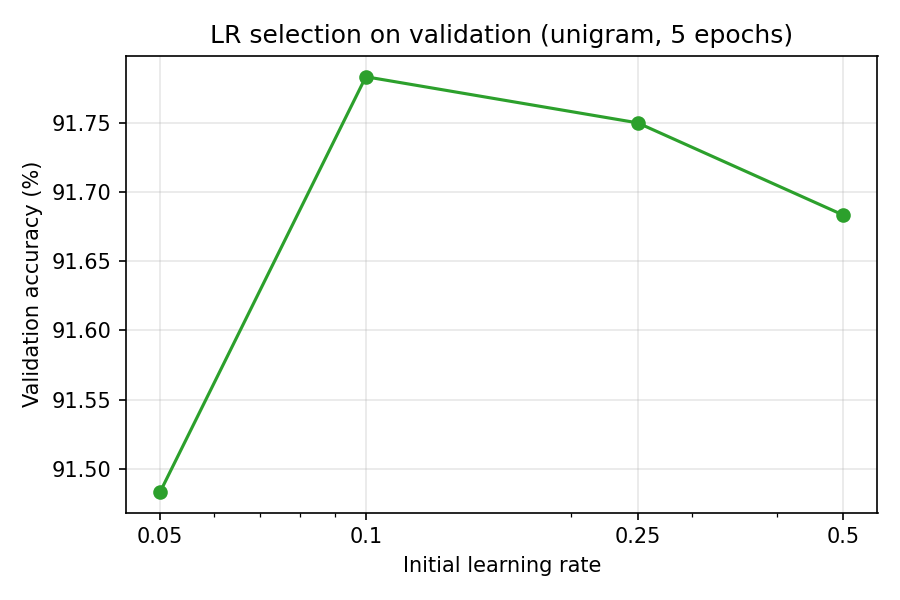

results/figures/lr_sweep_bigram.png


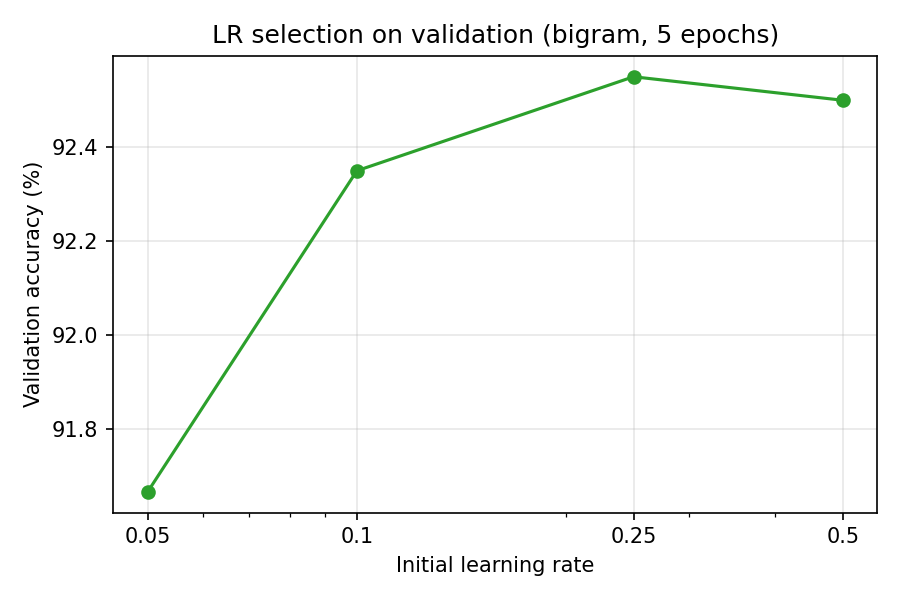

results/figures/fasttext_h10_bigram_train_loss.png


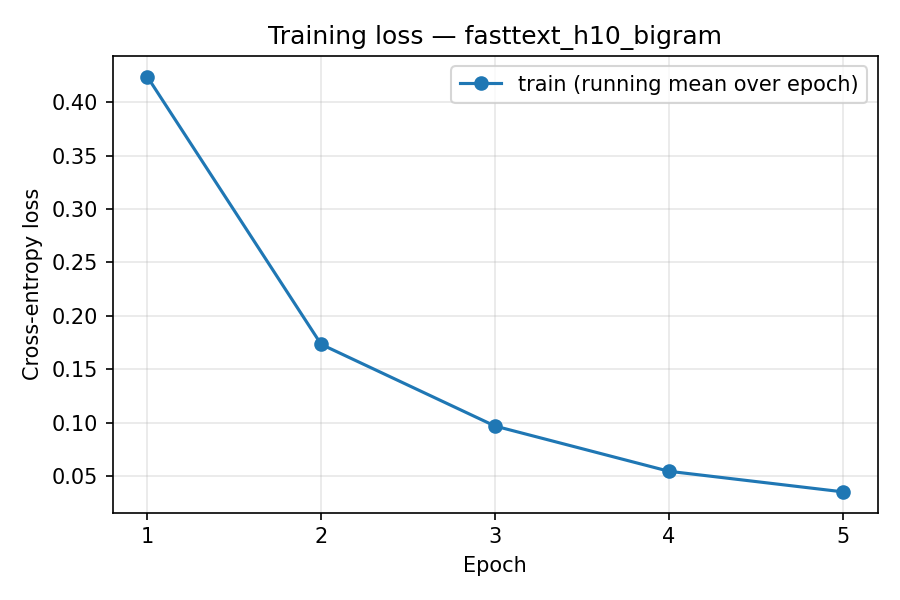

results/figures/fasttext_h10_bigram_val_loss.png


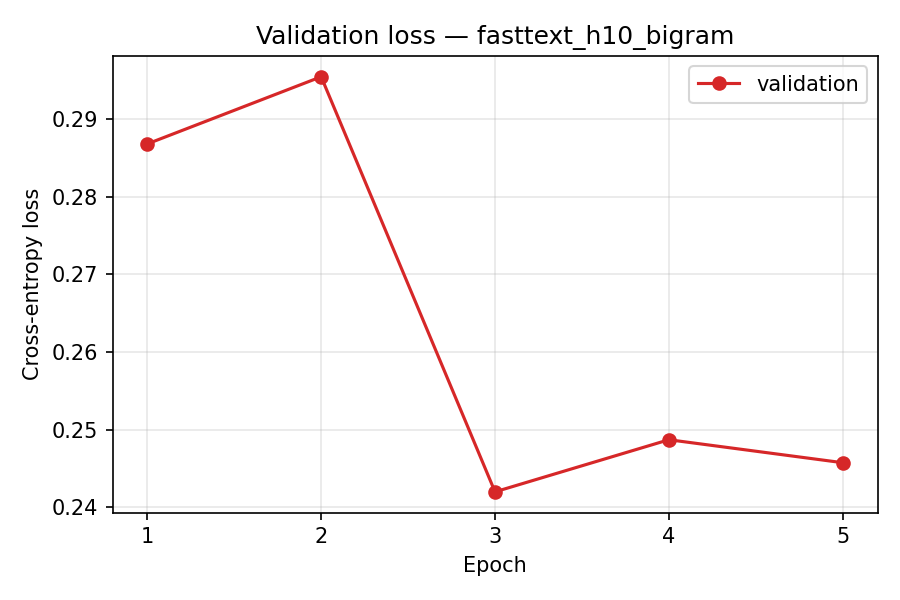

results/figures/fasttext_h10_bigram_accuracy.png


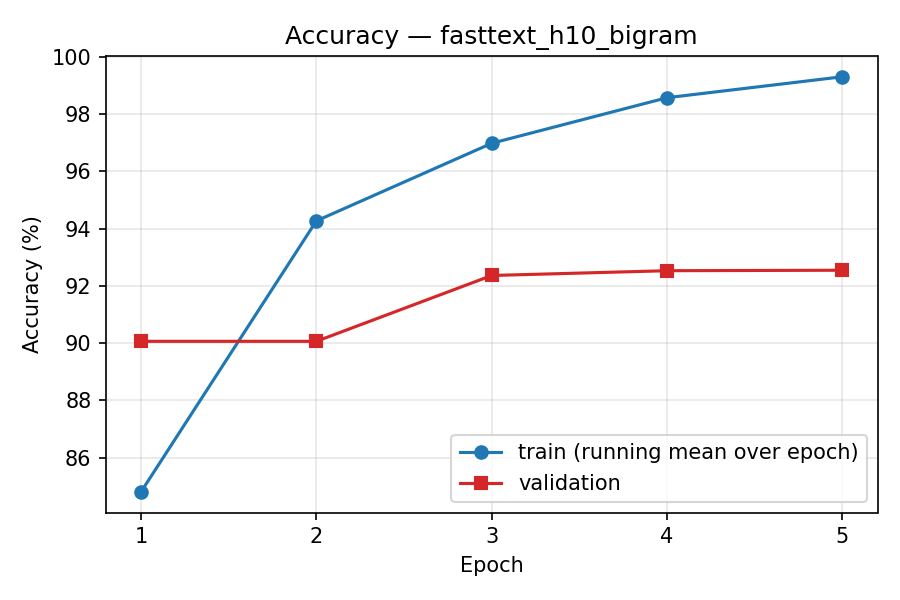

results/figures/fasttext_h10_bigram_confusion_matrix.png


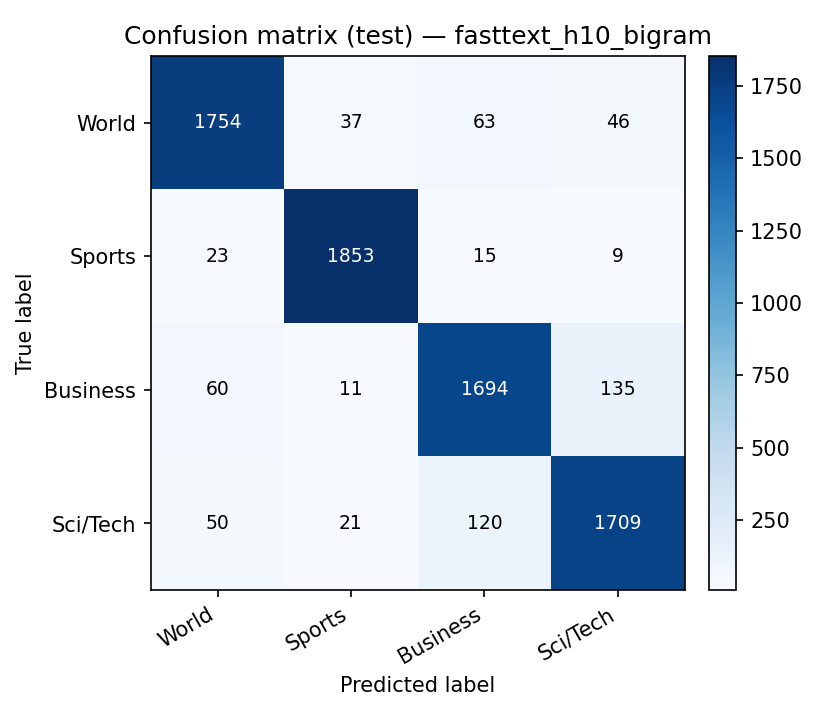

results/figures/fasttext_h10_bigram_confusion_matrix_normalized.png


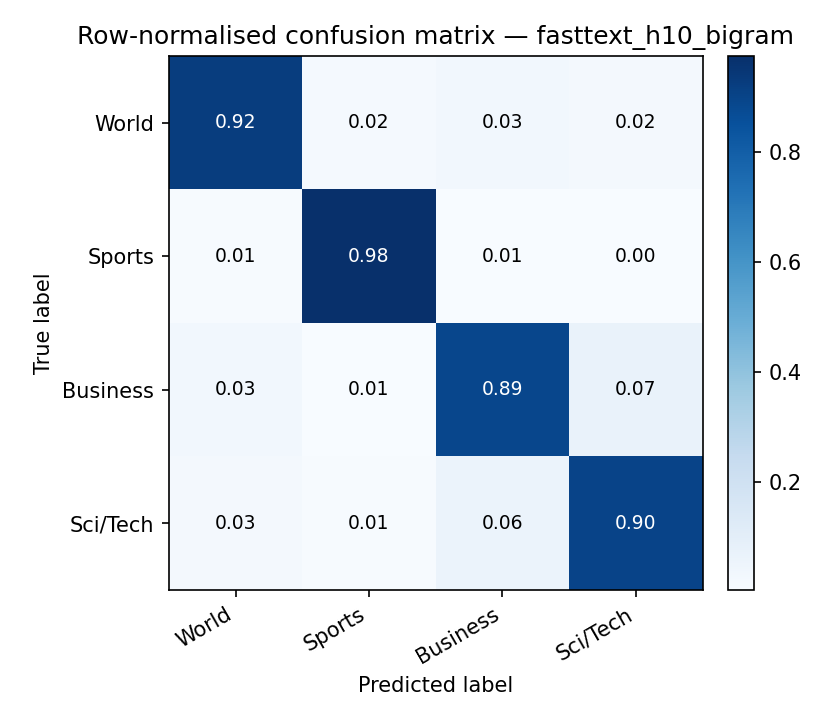

results/figures/fasttext_h10_unigram_loss.png


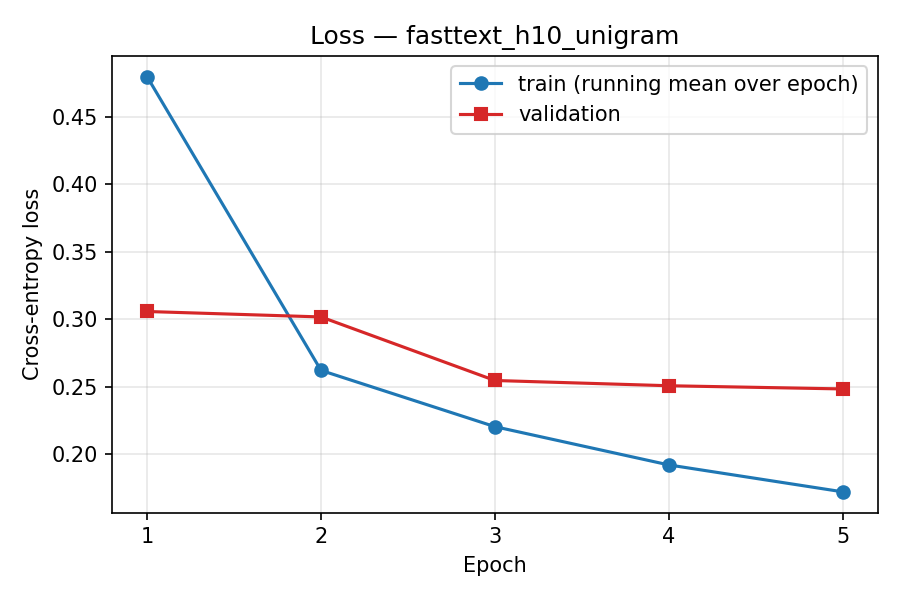

results/figures/fasttext_h10_unigram_accuracy.png


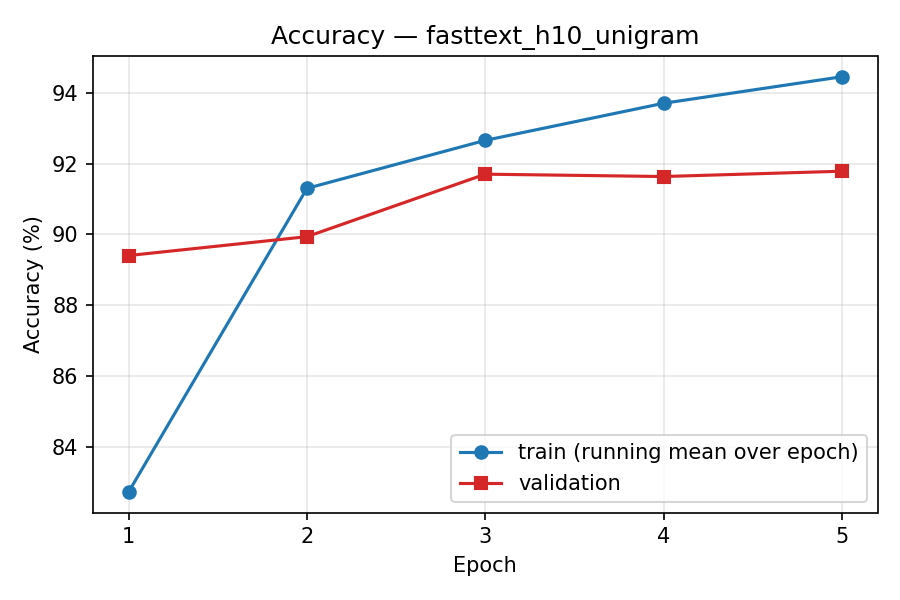

results/figures/fasttext_h10_unigram_confusion_matrix.png


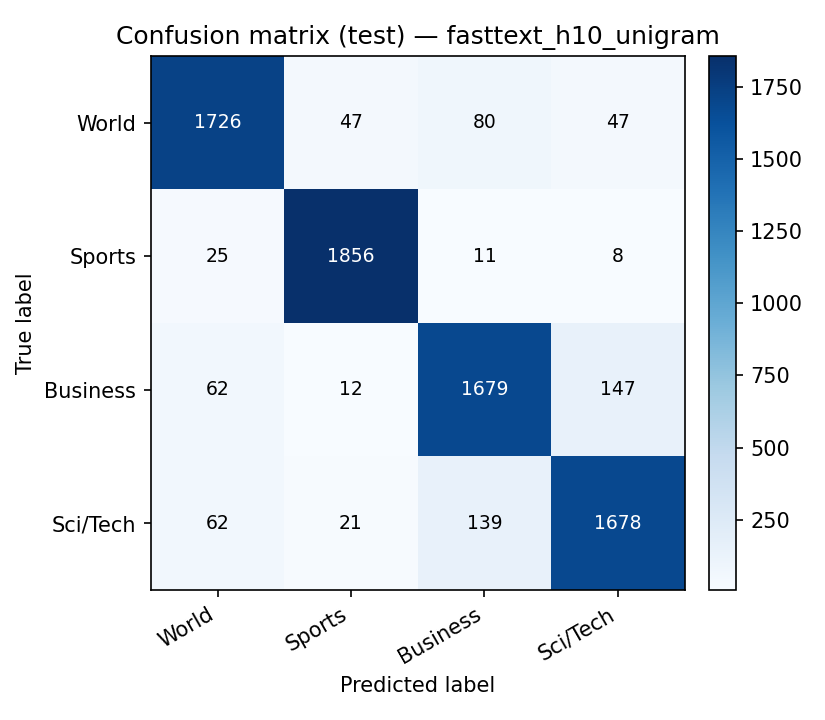

In [30]:
from IPython.display import Image, display
from pathlib import Path
os.chdir(REPO_DIR)
for name in ["lr_sweep_unigram", "lr_sweep_bigram",
             "fasttext_h10_bigram_train_loss", "fasttext_h10_bigram_val_loss", "fasttext_h10_bigram_accuracy",
             "fasttext_h10_bigram_confusion_matrix", "fasttext_h10_bigram_confusion_matrix_normalized",
             "fasttext_h10_unigram_loss", "fasttext_h10_unigram_accuracy", "fasttext_h10_unigram_confusion_matrix"]:
    p = Path("results/figures") / f"{name}.png"
    if p.exists():
        print(p); display(Image(filename=str(p), width=480))
    else:
        print("not found:", p)

In [31]:
import json
os.chdir(REPO_DIR)
for run in ["fasttext_h10_unigram", "fasttext_h10_bigram"]:
    print(f"==== {run} ====")
    print(open(f"results/metrics/{run}_classification_report.txt").read())

==== fasttext_h10_unigram ====
              precision    recall  f1-score   support

       World     0.9205    0.9084    0.9144      1900
      Sports     0.9587    0.9768    0.9677      1900
    Business     0.8795    0.8837    0.8816      1900
    Sci/Tech     0.8926    0.8832    0.8878      1900

    accuracy                         0.9130      7600
   macro avg     0.9128    0.9130    0.9129      7600
weighted avg     0.9128    0.9130    0.9129      7600

==== fasttext_h10_bigram ====
              precision    recall  f1-score   support

       World     0.9295    0.9232    0.9263      1900
      Sports     0.9641    0.9753    0.9696      1900
    Business     0.8953    0.8916    0.8935      1900
    Sci/Tech     0.8999    0.8995    0.8997      1900

    accuracy                         0.9224      7600
   macro avg     0.9222    0.9224    0.9223      7600
weighted avg     0.9222    0.9224    0.9223      7600



## Step 14 — Generate the reproducibility report

In [32]:
%cd {REPO_DIR}
!python -m src.report
from IPython.display import Markdown, display
display(Markdown(open("results/reproducibility_report.md").read()[:6000] + "\n\n*(truncated preview - open the file for the full report)*"))

/content
Report written to /content/fasttext-text-classification-reproduction/results/reproducibility_report.md (3796 words)
Updated results section of /content/fasttext-text-classification-reproduction/README.md


# Reproducibility Report: "Bag of Tricks for Efficient Text Classification" on AG News

*Generated automatically by `src/report.py` from the files in `results/metrics/`. All reproduced
numbers below come from the experiment logs of this repository; the original numbers are taken from
Table 1 and Table 2 of arXiv:1607.01759v3.*

---

## 1. Introduction

Text classification is one of the most common tasks in natural language processing: spam filtering,
topic labelling, sentiment analysis and intent detection all reduce to it. By 2016 the strongest
reported results on the standard large-scale benchmarks of Zhang et al. (2015) came from deep
convolutional and recurrent networks operating on characters or words, which needed GPUs and hours of
training per epoch. Joulin, Grave, Bojanowski and Mikolov (2016) argued that a carefully engineered
*linear* model, with a low-rank constraint, averaged word and n-gram embeddings, and a handful of
efficiency "tricks", reaches accuracy on par with these networks while training several orders of
magnitude faster on a CPU. Their method was released as the fastText library.

This report documents an independent re-implementation of that classifier in PyTorch and its evaluation
on the AG News topic-classification benchmark, one of the eight datasets in Table 1 of the paper. The goals
are (i) to check whether the reported AG News test accuracies (**91.5%** without and **92.5%** with bigrams)
can be obtained from the published description and the official scripts, (ii) to quantify every
deviation from the original setup, and (iii) to package the experiment so that it can be re-run end to
end on a CPU-only Google Colab instance and resumed after a disconnect.

The report is organised as follows. Section 2 summarises the paper; Sections 3–5 describe the method,
the implementation and the experimental setup; Sections 6–7 present the reproduced results and compare
them with the original ones; Section 8 discusses sources of discrepancy, and Sections 9–10 list
limitations and conclude.

## 2. Paper Overview

**Model.** A document is represented as a bag of features (words and, optionally, word n-grams). Each
feature indexes a row of an embedding matrix *A*; the rows are averaged into a hidden document
representation of size *h*, which is fed to a linear classifier *B* followed by a softmax. Training minimises
the negative log-likelihood

  −(1/N) Σₙ yₙ log(f(B A xₙ)),

where *xₙ* is the normalised bag of features of document *n*. The model is therefore a linear classifier
whose weight matrix is factorised into *B·A* (rank ≤ *h*), which lets parameters be shared across features
and classes. It is trained with stochastic gradient descent and a linearly decaying learning rate,
asynchronously on multiple CPU threads.

**Tricks.** (1) A *hierarchical softmax* based on a Huffman tree reduces the cost of the output layer from
O(kh) to O(h log₂ k) for *k* classes — important for tag prediction with hundreds of thousands of labels,
irrelevant for the 4 classes of AG News. (2) *N-gram features* add local word-order information that a pure
bag of words lacks. (3) The *hashing trick* (Weinberger et al., 2009) maps n-grams into a fixed number of
buckets (10M when only bigrams are used) instead of storing an explicit n-gram vocabulary.

**Experiments on AG News.** The sentiment/topic experiments use *h* = 10 hidden units, 5 epochs, and an
initial learning rate selected on a validation set from {0.05, 0.1, 0.25, 0.5}. Table 1 of the paper
reports AG News test accuracy of **91.5%** for fastText (h=10) and **92.5%** for fastText (h=10, bigram),
compared with 87.2% for char-CNN, 91.4% for char-CRNN and 91.3% for VDCNN. Table 2 reports a training
time of **1 s per epoch** on AG News for the bigram model (CPU, 20 threads) versus 1–3 h for char-CNN and
24–51 min for VDCNN on a Tesla K40 GPU.

**Official implementation.** The script `classification-results.sh` in the fastText repository reproduces
Table 1. For AG News it lowercases and tokenises the CSV files with a `sed` pipeline and runs
`fasttext supervised -dim 10 -lr 0.25 -wordNgrams 2 -minCount 1 -bucket 10000000 -epoch 5 -thread 4`.
It does not pass `-loss`, so the default (full) softmax is used. The script notes that its learning rates
"were chosen by validation on a subset of the training set".

## 3. Methodology

Our reproduction follows the paper and the official script step by step:

1. **Data.** The original AG News CSV files of Zhang et al. (2015): 120,000 training and 7,600 test
   documents, 4 balanced classes (World, Sports, Business, Sci/Tech). Each document is a title plus a
   short description. File integrity is verified with SHA-256 and row counts.
2. **Normalisation.** The official `normalize_text` function is reproduced exactly (ASCII lowercasing,
   separating `. , ( ) ! ?` and apostrophes, removing quotes, `;` and `:`). Because the official script
   operates on the raw CSV line, the field separators become `,` tokens; we reproduce this too.
3. **Features.** Unigrams from a training-set vocabulary (minCount = 1) plus an end-of-line token
   `</s>`. In the bigram model, every pair of consecutive tokens is hashed with fastText's own
   hash functions into 10M buckets. Out-of-vocabulary test words are dropped as unigrams but still
   contribute to bigrams, exactly as in the C++ code.
4. **Model.** Averaged embedding bag (h = 10) → linear layer (no bias) → softmax cross-entropy.
   Initialisation as in fastText: *A* ~ U(−1/h, 1/h), *B* = 0.
5. **Optimisation.** SGD with the learning rate decaying linearly to zero over the total number of
   training tokens across 5 epochs.
6. **Model selection.** Following the paper, the initial learning rate is chosen from {0.05, 0.1, 0.25, 0.5}
   by accuracy on a held-out validation split, separately for the unigram and bigram models.
7. **Evaluation.** The model after the 5th epoch (no early stopping) is evaluated once on the official
   test set. We report accuracy (the paper's

*(truncated preview - open the file for the full report)*

## Step 15 — Save logs, checkpoints and this notebook

In [ ]:
import json, os, shutil
os.chdir(REPO_DIR)
ckpt_root = os.environ.get("FT_CHECKPOINT_DIR", "checkpoints")
!ls -la {ckpt_root}/* 2>/dev/null; du -sh {ckpt_root} 2>/dev/null

try:
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
    with open("notebooks/reproduction_experiment.ipynb", "w", encoding="utf-8") as f:
        json.dump(nb, f, indent=1, ensure_ascii=False)
    print("Notebook saved to notebooks/reproduction_experiment.ipynb")
except Exception as e:
    print("Could not save the notebook automatically:", e)

/content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/checkpoints/fasttext_h10_bigram:
total 394305
drwx------ 2 root root      4096 Nov  8 14:24 .
drwx------ 4 root root      4096 Nov  8 14:23 ..
-rw------- 1 root root 403759247 Nov  8 14:24 final.pt

/content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/checkpoints/fasttext_h10_unigram:
total 3680
drwx------ 2 root root    4096 Nov  8 14:23 .
drwx------ 4 root root    4096 Nov  8 14:23 ..
-rw------- 1 root root 3759247 Nov  8 14:23 final.pt
389M	/content/drive/MyDrive/fasttext-text-classification-reproduction_artifacts/checkpoints


## Step 16 — Commit and push to GitHub

In [47]:
os.chdir(REPO_DIR)

# Securely update the active token in the process environment
os.environ['GITHUB_TOKEN'] = GITHUB_TOKEN

# Reset the remote URL to the clean URL without hardcoded credentials
sh(f"git remote set-url origin {REPO_URL}")

sh("git add -A")
sh("git status --short")
if sh("git diff --cached --quiet", check=False).returncode != 0:
    sh('git commit -q -m "fastText reproduction on AG News: code, results, figures and report"')
else:
    print("Nothing new to commit")

# Push safely using the dynamic in-memory credential helper
sh(f"git {GIT_AUTH} push -u origin {BRANCH}")

# Safety check: ensure no token was committed or saved to disk
tok = os.environ.get("GITHUB_TOKEN", "")
leak = tok and (sh(f"git grep -q -F -e \"$GITHUB_TOKEN\" HEAD", check=False).returncode == 0
                or tok in open(".git/config").read())
print("Token leak check:", "FOUND - revoke the token immediately!" if leak else "clean")
sh("git log --oneline -n 5")
print(f"\nDone: https://github.com/{REPO_OWNER}/{REPO_NAME}")

Nothing new to commit
branch 'main' set up to track 'origin/main'.
To https://github.com/nikhatraghna/fasttext-text-classification-reproduction.git
 * [new branch]      main -> main
Token leak check: clean
7f1bde3 fastText reproduction on AG News: code, results, figures and report

Done: https://github.com/nikhatraghna/fasttext-text-classification-reproduction


In [49]:
!git status


On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
